## Evoluzione delle anime negli anni

Gli anime non sono solo titoli da guardare: sono un ecosistema fatto di produzione, generi, personaggi, voci, fan e comunità globali.

In questo notebook racconteremo come questo ecosistema prende forma nei dati: dalla crescita storica degli anime fino al modo in cui gli utenti li valutano, li amano e li organizzano nelle proprie liste.

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
import ast
import plotly.express as px
from solution.utils import utils

In [2]:
# load dataset
df_details = pd.read_csv("../../dataset/cleaned/details_cleaned.csv")
df_favs = pd.read_csv("../../dataset/cleaned/favs_cleaned.csv")
df_recommendations = pd.read_csv("../../dataset/cleaned/recommendations_cleaned.csv")
df_stats = pd.read_csv("../../dataset/cleaned/stats_cleaned.csv")
df_ratings = pd.read_csv("../../dataset/cleaned/ratings_cleaned.csv")
df_profiles = pd.read_csv("../../dataset/cleaned/profiles_cleaned.csv")
df_person_anime_works = pd.read_csv("../../dataset/cleaned/person_anime_works_cleaned.csv")
df_person_details = pd.read_csv("../../dataset/cleaned/person_details_cleaned.csv")
df_person_alternate_names = pd.read_csv("../../dataset/cleaned/person_alternate_names_cleaned.csv")
df_characters_anime_works = pd.read_csv("../../dataset/cleaned/character_anime_works_cleaned.csv")
df_person_voice_works = pd.read_csv("../../dataset/cleaned/person_voice_works_cleaned.csv")
df_characters = pd.read_csv("../../dataset/cleaned/characters_cleaned.csv")
df_character_nicknames = pd.read_csv("../../dataset/cleaned/character_nicknames_cleaned.csv")

In [3]:
df_details['start_date'] = pd.to_datetime(df_details['start_date'], errors='coerce')
df_details['year'] = df_details['start_date'].dt.year.astype("Int64")
df_details['scored_by'] = pd.to_numeric(df_details['scored_by'], errors='coerce')
df_person_details["birthday"] = pd.to_datetime(df_person_details["birthday"], errors="coerce")
df_person_details["birth_year"] = df_person_details["birthday"].dt.year.astype("Int64")
df_person_details["favorites"] = pd.to_numeric(df_person_details["favorites"], errors="coerce")

## 1. LA CRESCITA STORICA DELLA PRODUZIONE ANIME

### 1.1 Come si è evoluta la produzione di anime nel tempo?

In [4]:
details = df_details.copy()
details = details.dropna(subset=['start_date'])

# Conteggio anime per anno
counts = (details['year'].value_counts().sort_index().reset_index())
counts.columns = ['year', 'anime_count']

fig = px.line(counts,x='year',y='anime_count',markers=True,
    title="Numero di anime per anno di inizio",
    labels={'year': 'Anno di inizio','anime_count': 'Numero di anime'},
    hover_data={'year': True,'anime_count': True})
fig.update_traces(marker=dict(size=5),line=dict(width=2))
fig.update_layout(
    xaxis=dict(range=[1917, 2024]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

**La parabola della produzione: dal silenzio all'esplosione**

Per gran parte del Novecento, l'industria degli anime ha proceduto con un passo lento e constante. è stato un cammino silenzioso, fatto di sperimentazione e artigianalità, dove la produzione cresceva senza scosse evidenti. Ma è con l'arrivo degli anni '80 che qualcosa inizia a cambiare: il battito accelera, segnalando un interesse che travalica i confini nazionali.

**Il Nuovo Millennio e il picco storico**

Tuttavia, è dopo il 2000 che assistiamo a una vera e propria metamorfosi. La curva della produzione cambia ritmo in modo prepotente, spinta dalla digitalizzazione e da una domanda globale sempre più vorace. Questo crescendo culmina nel **2017**: l'anno d'oro, il vertice masssimo di un'espansione durata due decenni, in cui l'industria ha toccato il suo apice storico.

**Oltre la vetta: un nuovo equilibro**

Negli anni più recenti, i dati mostrano una lieva flessione. Non è però un segnale di crisi, ma il riflesso di un mercato che, dopo aver toccato vette incredibile nel 2017, cerca ora un nuovo equilibro. La tendenza generale rimane solida: il gigante è sveglio e continua a correre, consolidando la sua eredigtà come ecosistema culturale globale.

### 1.2 L'albero genealogico degli anime: distribuzione dei generi

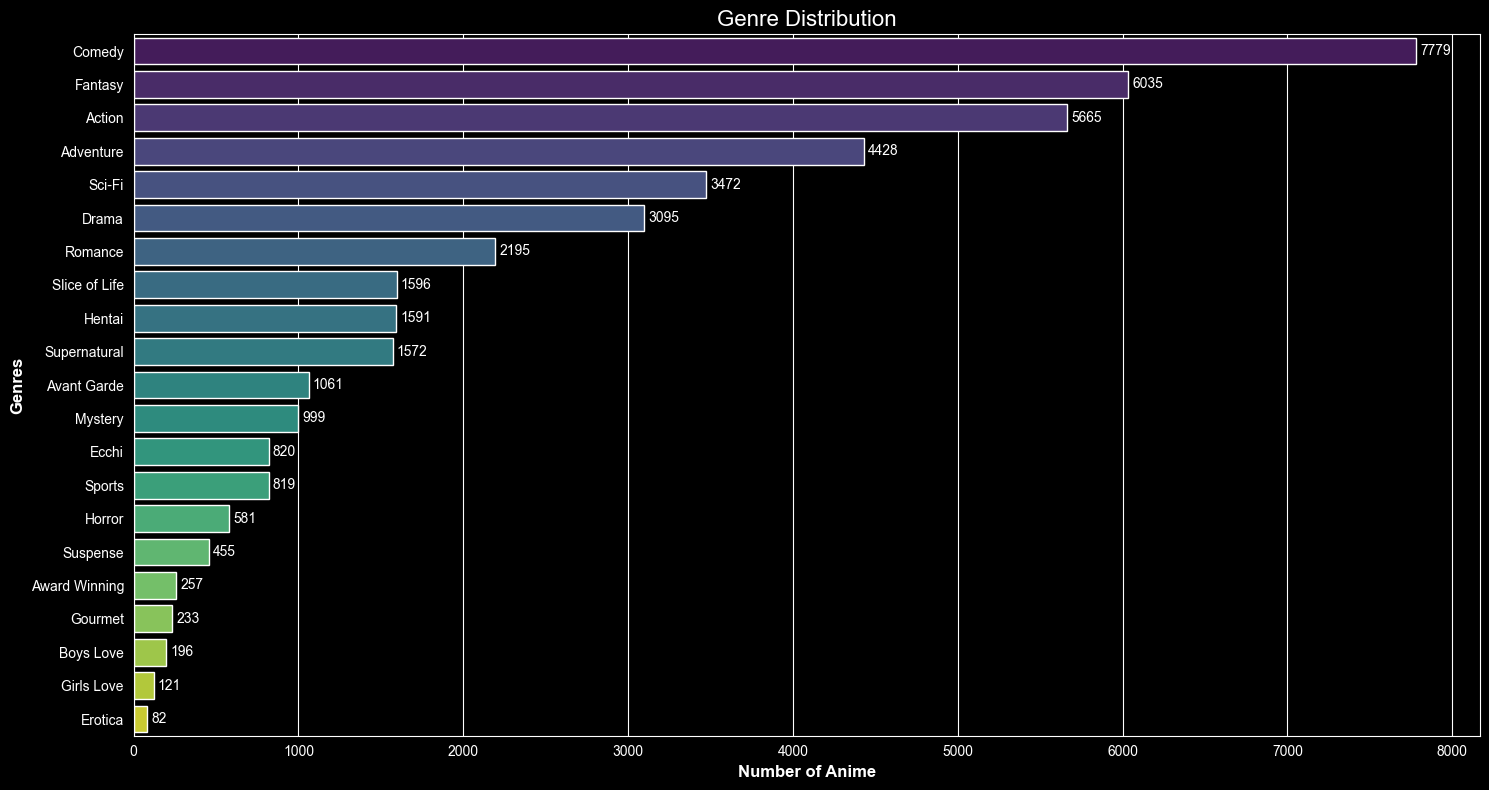

In [5]:
df_genres = df_details['genres'].copy()
df_genres = df_genres.apply(ast.literal_eval)

df_genres = df_genres.explode().dropna()
genre_count = df_genres.value_counts().reset_index()

genre_count.columns = ['genre', 'count']
# plot
plt.figure(figsize=(15, 8))
ax = sns.barplot(data=genre_count, x='count', y='genre', hue='genre', palette='viridis')
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Genre Distribution', fontsize=16)
plt.xlabel('Number of Anime', fontsize=12, fontweight='bold')
plt.ylabel('Genres', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


**I giganti del settore: i pilastri del mercato**
Se osserviamo la foresta dei contenuti prodotti, i giganti che dominano la scena sono indubbiamente la **Commedia**, l'**Azione** e il **Fantasy**. Questi generi costituiscono le fondamenta dell'intera industria: la loro popolarità universale li rende i prodotti più "sicuri" e richiesti, capaci di attrarre un pubblico vastissimo che spazia dai giovanissimi ai fan storici.

**L'equilibrio tra evasione e introspezione**

Accanto ai leader indiscussi, notiamo una presenza solida di generi come **Adventure** e **Sci-Fi**, che alimentano l'immaginario fantastico tipico del medium. Tuttavia, l'analisi rivela che non c'è solo spettacolo: il successo di titoli **Drama** e **Slice of Life** dimostra un'industria profondamente radicata nell'esplorazione dei sentimenti umani e della vita quotidiana, capace di trasformare la normalità in narrazione epica.

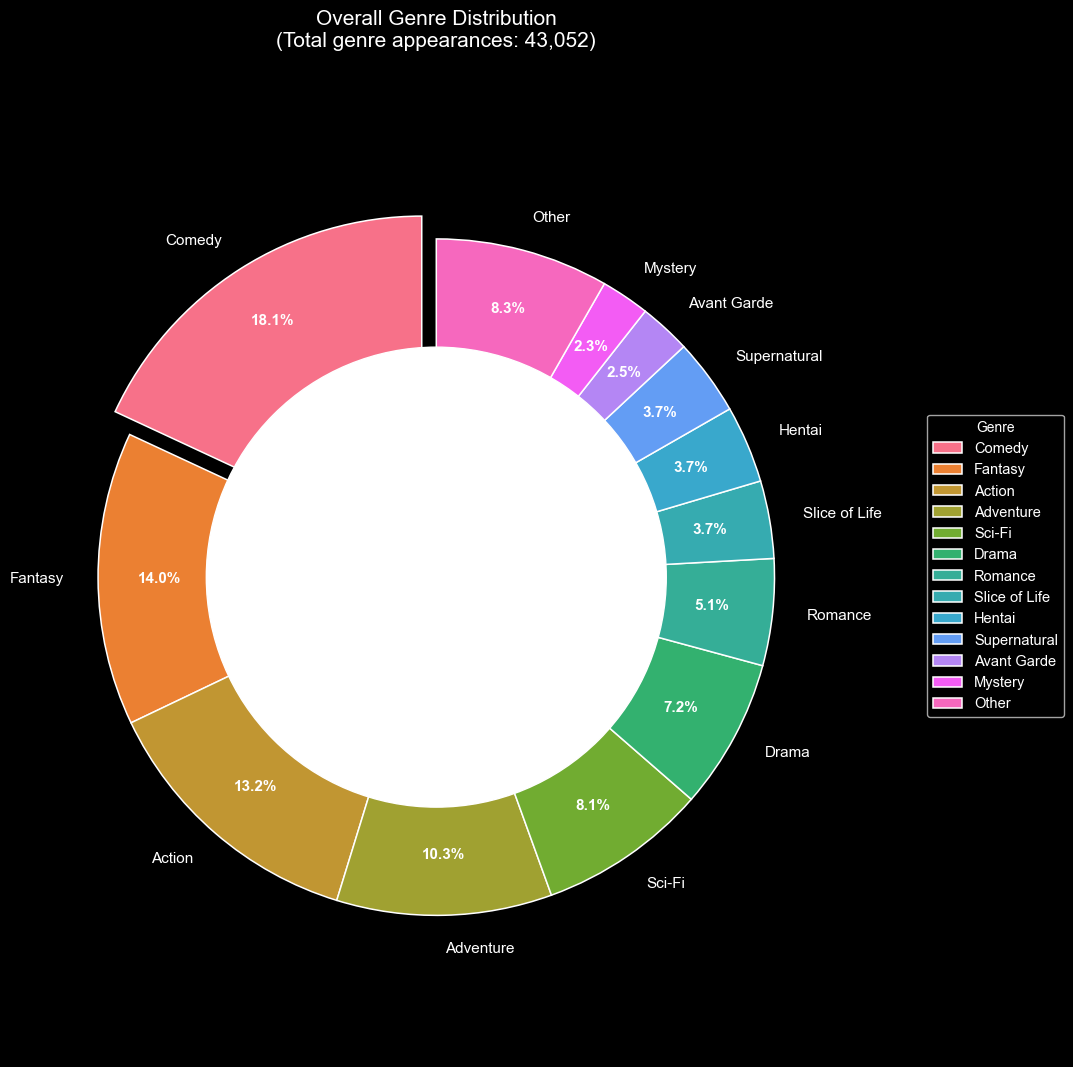

In [6]:
details = df_details.copy()
details = details.dropna(subset=['genres'])
details['genres'] = details['genres'].apply(utils.parse_genres)
# Explode: una riga per ogni genere
genres_df = details.explode('genres')
# Conta quante volte compare ogni genere
genre_total = genres_df['genres'].value_counts()
# Top 12 generi + Other
top_n_pie = 12
top_genres_pie = genre_total.head(top_n_pie)
other_count = genre_total.iloc[top_n_pie:].sum()

if other_count > 0:
    pie_data = pd.concat([
        top_genres_pie,
        pd.Series({'Other': other_count})
    ])
else:
    pie_data = top_genres_pie

plt.figure(figsize=(11, 11))
colors = sns.color_palette("husl", len(pie_data))

# Explode solo sulla fetta più grande
explode = [0.08 if genre == pie_data.idxmax() else 0 for genre in pie_data.index]

wedges, texts, autotexts = plt.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=explode,
    pctdistance=0.82,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.1},
    textprops={'fontsize': 11}
)

# Stile percentuali
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

plt.title(f"Overall Genre Distribution\n(Total genre appearances: {genre_total.sum():,})",fontsize=15, pad=20)
# Effetto donut
centre_circle = plt.Circle((0, 0), 0.68, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
# Legenda
plt.legend(pie_data.index, title="Genre", loc="center left",bbox_to_anchor=(1.15, 0.5), fontsize=10.5)
plt.axis('equal')
plt.tight_layout()
plt.show()

**L'anima del mosaico: la forza delle nicchie**

Il grafico a ciambella ci offre una prospettiva diversa e fondamentale: quella della "biodiversità" del settore. Sebbene i generi dominanti occupino le fette più grandi, la vasta area definita dalle categorie minori rivela la vera magia degli anime. Non è un mercato a senso unico, ma un mosaico composto da centinaia di sfumature diverse che convivono armoniosamente.

**Visione d'insieme: un ecosistema multiforme**

In sintesi, l'equilibrio tra i generi **mainstream** (che garantiscono la stabilità economica) e le innumerevoli **nicchie** (che preservano la vivacità artistica) è il vero segreto del successo globale. Questa distribuzione ci restituisce l'immagine di un ecosistema maturo, dove ogni spettatore, indipendentemente da quanto siano particolari i suoi gusti, potrà sempre trovare una storia originale cucita su misura per lui.

### Come sono cambiati i generi anime nel tempo?

In [7]:
df_gen_evol = df_details.copy()
df_gen_evol = df_gen_evol.dropna(subset=['year'])
df_gen_evol = df_gen_evol[(df_gen_evol['year'] >= 1917) & (df_gen_evol['year'] <= 2024)]
df_gen_evol = df_gen_evol.dropna(subset=['genres'])
df_gen_evol['genres'] = df_gen_evol['genres'].apply(utils.parse_genres)
df_gen_evol['genres'] = df_gen_evol['genres'].apply(lambda g: [gen.strip().title() for gen in g])

# explode generi
genres_df = df_gen_evol.explode('genres')
# conteggio per anno e genere
genre_year = (genres_df.groupby(['year', 'genres']).size() .reset_index(name='count'))
# grafico
fig = go.Figure()
for genre in sorted(genre_year['genres'].unique()):
    df_g = genre_year[genre_year['genres'] == genre]
    fig.add_trace(
        go.Scatter(
            x=df_g['year'],
            y=df_g['count'],
            mode='lines',
            name=genre,
            visible=True if genre == "Action" else "legendonly",
            line=dict(width=2.5)
        )
    )
fig.update_layout(
    title="Anime production over time by genre",
    xaxis_title="Year",
    yaxis_title="Number of anime released",
    template="plotly_dark",
    hovermode="x unified",
    legend_title="Click genres to show / hide"
)
fig.show()

Il grafico mostra come i principali generi anime si siano evoluti nel corso degli anni, seguendo traiettorie diverse ma con un andamento comune: una crescita lenta fino agli anni ’70, seguita da un’accelerazione evidente a partire dagli anni ’80. In questa fase, generi come _Action_, _Adventure_, _Comedy_ e _Drama_ iniziano a distinguersi, aumentando progressivamente la loro presenza.
Dopo il 2000, tutte le linee mostrano un incremento più marcato, segno di un’espansione generale dell’industria. In particolare, **Comedy** e **Action** emergono come i generi più dinamici, ma con caratteristiche diverse: la Comedy cresce in modo più rapido e raggiunge valori più elevati, mentre l’Action mantiene un andamento più regolare e costante, confermandosi come uno dei pilastri storici della produzione anime. Il 2017 rappresenta un punto particolarmente significativo: in quell’anno, diversi generi tra cui proprio Comedy e Action  toccano uno dei loro massimi, evidenziando un momento di forte intensificazione produttiva.
Negli anni successivi, alcune curve mostrano una lieve flessione, mentre altre mantengono livelli elevati, suggerendo un settore che continua a essere attivo ma con ritmi più equilibrati rispetto al picco precedente.
Nel complesso, il grafico racconta una storia di crescita condivisa, in cui ogni genere segue il proprio percorso ma contribuisce a un’espansione complessiva dell’animazione giapponese.

## 2. DALLA PRODUZIONE ALLA VALUTAZIONE DEGLI UTENTI

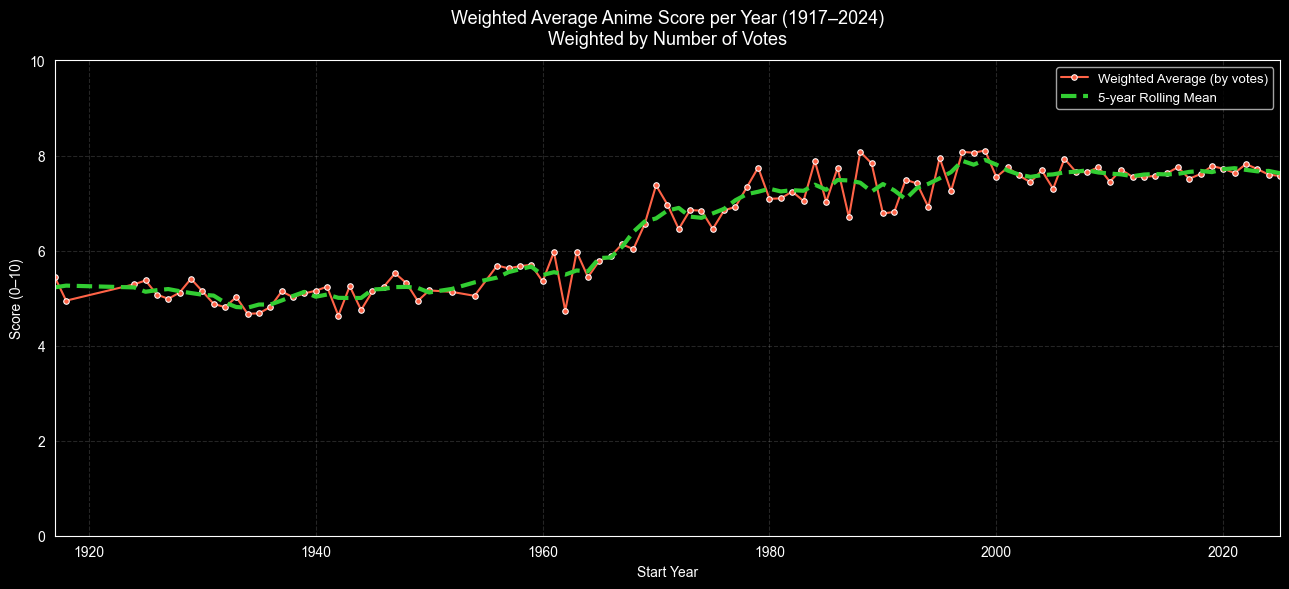

In [8]:
details = df_details.copy()
# filtro per il calcolo della media pesata
df_weighted = details[
    details['score'].notna() &
    details['scored_by'].notna() &
    (details['scored_by'] > 0) &
    details['year'].notna()
].copy()
# limitiamo l'analisi agli anni con dati storicamnete rilevanti
df_weighted = df_weighted[df_weighted['year'] >= 1917]
# calcolo di media dei punteggi, totale dei voti, numero di anime rilasciati
year_weighted = df_weighted.groupby('year', group_keys=False).apply(
    lambda x: pd.Series({
        'weighted_mean': (x['score'] * x['scored_by']).sum() / x['scored_by'].sum(),
        'total_votes': x['scored_by'].sum(),
        'anime_count': len(x)
    }),
    include_groups=False
).reset_index()
# Ordina per sicurezza
year_weighted = year_weighted.sort_values('year')
# calcoliamo una media mobile centrata su 5 anni per rendere il trend più leggibile
year_weighted['rolling_weighted'] = year_weighted['weighted_mean'].rolling(window=5, center=True, min_periods=2).mean()
# visualizzazione
plt.figure(figsize=(13, 6))
# Linea principale: media pesata
sns.lineplot(data=year_weighted,x='year',y='weighted_mean',color='tomato',linewidth=1.5,marker='o',markersize=4,label='Weighted Average (by votes)')
# media mobile
plt.plot(
    year_weighted['year'],
    year_weighted['rolling_weighted'],
    color='limegreen',
    linewidth=3,
    linestyle='--',
    label='5-year Rolling Mean'
)
plt.title("Weighted Average Anime Score per Year (1917–2024)\nWeighted by Number of Votes",fontsize=13,pad=12)
plt.xlabel("Start Year")
plt.ylabel("Score (0–10)")
# limiti degli assi per una scala coerente
plt.xlim(year_weighted['year'].min(), year_weighted['year'].max())
plt.ylim(0, 10)

plt.grid(True, alpha=0.15, linestyle='--')
plt.legend(fontsize=9.5)
plt.tight_layout()
plt.show()

Il grafico mostra l’andamento del punteggio medio degli anime dal 1917 al 2024, calcolato come media pesata sul numero di voti, così da dare maggiore importanza ai titoli più rilevanti per il pubblico.

Nei primi decenni la qualità media si mantiene su valori bassi e stabili, riflettendo una fase iniziale e sperimentale dell’industria. A partire dagli anni ’60 si osserva invece una crescita progressiva e significativa, in parallelo allo sviluppo dell’anime moderno e al consolidamento degli studi di animazione.

Dagli anni ’90 in poi, il punteggio medio raggiunge valori elevati e tende a stabilizzarsi, come evidenziato dalla media mobile a 5 anni. Questo suggerisce che, nonostante l’aumento della produzione, la qualità percepita dagli utenti rimane costante nel tempo, indicando una fase di maturità dell’industria anime.


### I generi più prodotti sono anche quelli più amati dai fan?

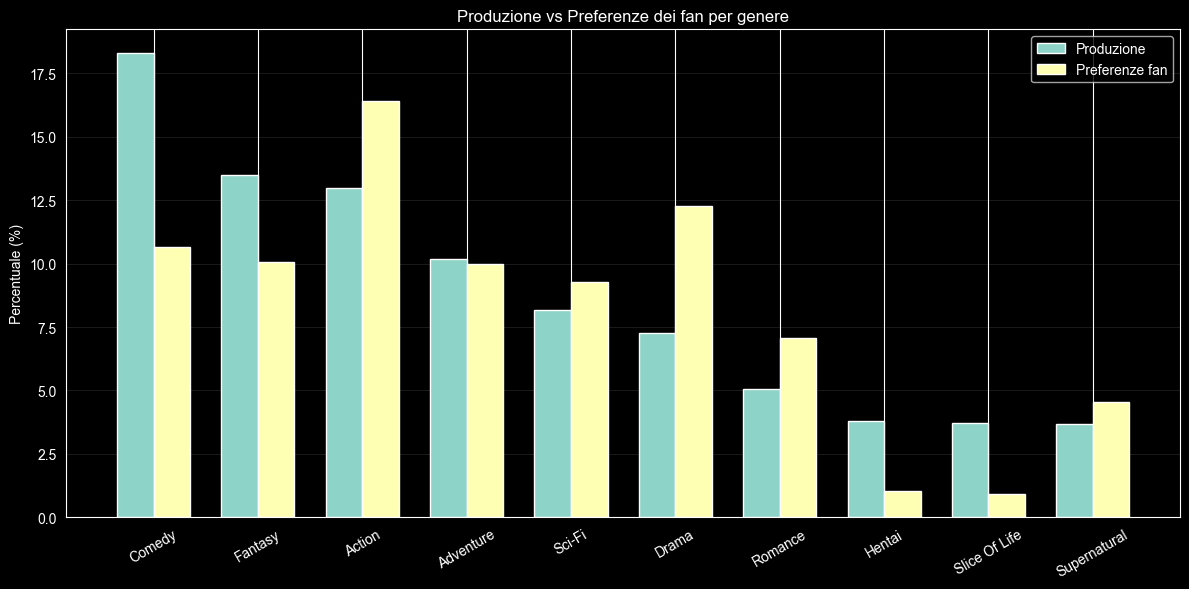

In [9]:
favs = df_favs.copy()
production = genres_df['genres'].value_counts()
production_pct = production / production.sum() * 100

favs_genres = pd.merge(favs, genres_df[['mal_id', 'genres']], on='mal_id', how='inner')
favs_count = favs_genres['genres'].value_counts()
favs_pct = favs_count / favs_count.sum() * 100

compare = pd.DataFrame({'Production (%)': production_pct, 'Fan Preferences (%)': favs_pct}).dropna()
compare = compare.sort_values('Production (%)', ascending=False).head(10)

x = np.arange(len(compare))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width / 2, compare['Production (%)'], width, label='Produzione')
plt.bar(x + width / 2, compare['Fan Preferences (%)'], width, label='Preferenze fan', )
plt.xticks(x, compare.index, rotation=30)
plt.ylabel("Percentuale (%)")
plt.title("Produzione vs Preferenze dei fan per genere")
plt.legend()
plt.grid(axis='y', alpha=0.1)
plt.tight_layout()
plt.show()

Il grafico mette a confronto la percentuale di produzione degli anime per genere con le preferenze dichiarate dai fan, evidenziando in modo immediato le aree di allineamento e quelle di discrepanza. Alcuni generi, come **Comedy** e **Fantasy**, mostrano una produzione molto elevata, ma non sempre corrispondono a un interesse dei fan altrettanto forte, suggerendo una sovraofferta rispetto alla domanda.
Al contrario, generi come **Drama** o **Romance** presentano una distanza più contenuta tra ciò che viene prodotto e ciò che il pubblico preferisce, indicando un equilibrio più stabile. In altri casi, come _Hentai_ o _Slice of Life_, la produzione risulta superiore alle preferenze, mentre generi come Supernatural mostrano un rapporto più armonico tra offerta e gradimento.
Nel complesso, il grafico racconta una dinamica interessante: l’industria tende a investire maggiormente nei generi più versatili e commerciali, mentre le preferenze dei fan risultano più distribuite e talvolta orientate verso generi meno rappresentati. Questa differenza tra produzione e domanda offre uno spunto utile per comprendere come il mercato anime si adatti o talvolta non si adatti alle aspettative del pubblico.

## 3. LE ORIGINI NARRATIVE DEGLI ANIME

### Da dove nascono -----

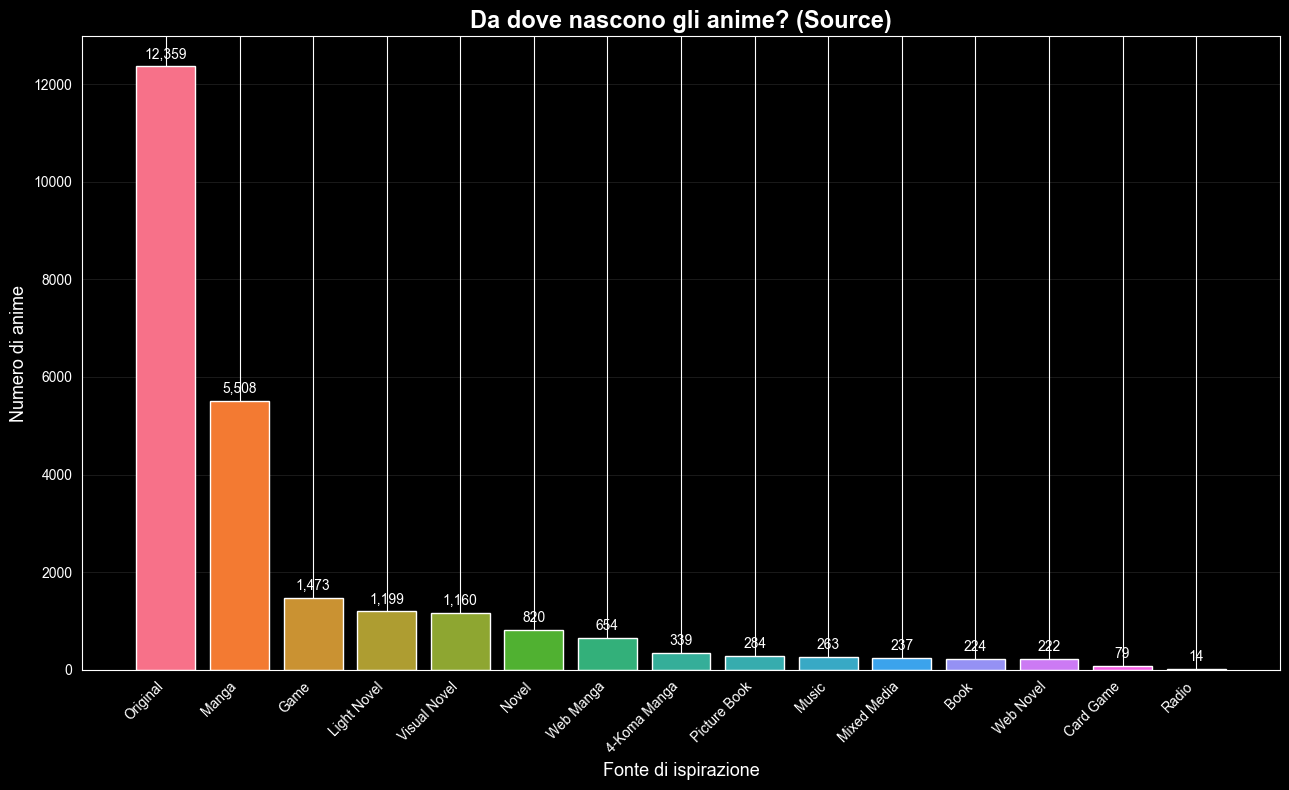

In [10]:
details = df_details.copy()
# filtro categoria unknown
details = details[(details['source'].notna()) & (details['source'] != 'Unknown') & (details['source'] != 'Other')]
details['source'] = details['source'].str.strip().str.title()
source_counts = (details['source'].value_counts().reset_index())
source_counts.columns = ['source', 'count']
# grafico
plt.figure(figsize=(13, 8))

colors = sns.color_palette("husl", n_colors=len(source_counts))

bars = plt.bar(source_counts['source'], source_counts['count'], color=colors)

# Aggiunge i numeri sopra ogni barra
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 100,
             f'{int(height):,}', ha='center', va='bottom', fontsize=10)

plt.xlabel("Fonte di ispirazione", fontsize=13)
plt.ylabel("Numero di anime", fontsize=13)
plt.title("Da dove nascono gli anime? (Source)", fontsize=17, fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.1)

plt.tight_layout()
plt.show()

Il grafico mostra la distribuzione delle principali **fonti di ispirazione** degli anime, evidenziando da quali media o opere originali nasce la produzione animata giapponese.

Il dato più evidente è la **forte predominanza delle opere Original**, che rappresentano la quota maggiore. Questo suggerisce che l’industria anime mantiene una notevole capacità creativa autonoma, producendo contenuti non direttamente derivati da altri media.

Subito dopo emergono gli adattamenti da **Manga**, che confermano il ruolo centrale di questo medium come serbatoio narrativo per l’animazione giapponese. Manga e anime risultano quindi profondamente interconnessi, sia dal punto di vista artistico che industriale.

Le altre categorie (come **Light Novel**, **Game**, **Visual Novel** e **Web Manga**) hanno una presenza più contenuta ma significativa, indicando una crescente tendenza alla contaminazione tra media diversi. Questo fenomeno riflette l’evoluzione del consumo culturale, sempre più crossmediale.

Nel complesso, il grafico racconta un’industria che combina **creatività originale** e **adattamento strategico**, bilanciando innovazione e sicurezza commerciale.


## 4. POPOLARITA' E IMPATTO CULTURALE

### In quali anni emergono gli anime più popolari?

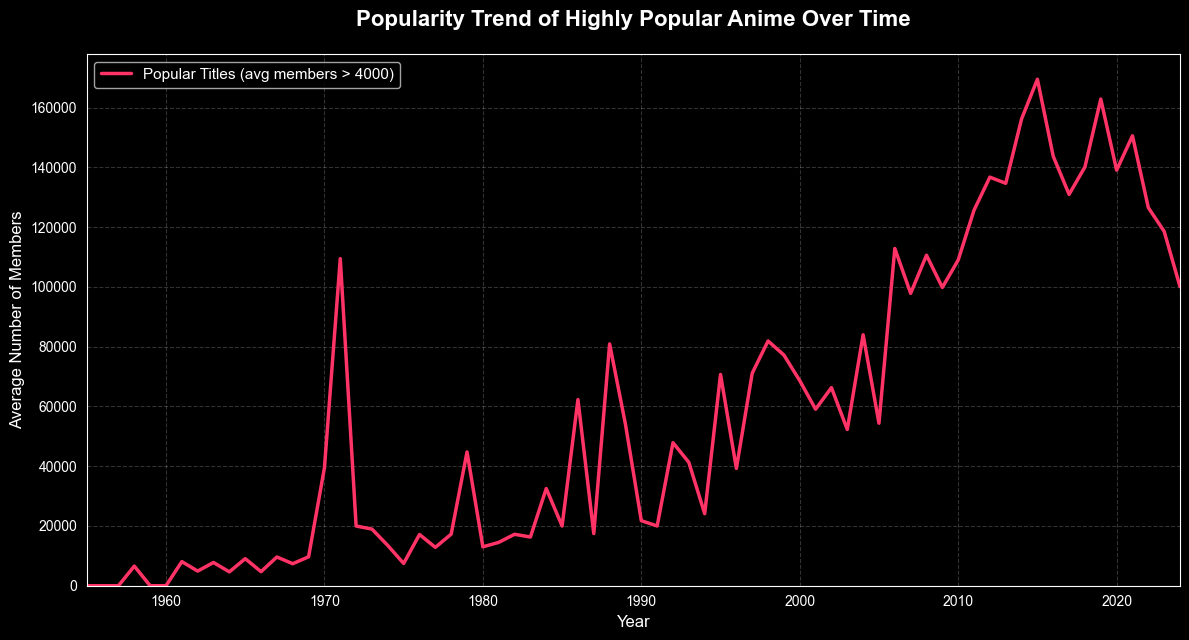

In [11]:
details = df_details.copy()

popular_pop = (details[details['members'] > 4000].groupby('year')['members'].mean().reindex(range(1955, 2025), fill_value=0).reset_index())

plt.figure(figsize=(12, 6.5))
plt.plot(
    popular_pop['year'],
    popular_pop['members'],
    color='#FF3366',
    linewidth=2.5,
    label='Popular Titles (avg members > 4000)'
)

plt.title('Popularity Trend of Highly Popular Anime Over Time',
          fontsize=16,
          fontweight='bold',
          pad=20)

plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Number of Members', fontsize=12)
plt.grid(True, alpha=0.2, linestyle='--')
plt.legend(fontsize=11, loc='upper left')
plt.xlim(1955, 2024)
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()

Il grafico mostra l’andamento della popolarità degli anime più seguiti nel corso di diversi decenni, misurata attraverso il numero medio di membri. La linea evidenzia un percorso irregolare ma significativo: nei primi anni la popolarità rimane contenuta, con oscillazioni limitate e valori relativamente bassi.
A partire dagli anni ’70 compaiono i primi picchi, seguiti da un nuovo aumento verso la fine degli anni ’80, segno di un interesse crescente e di titoli che iniziano a raggiungere un pubblico più ampio. Tuttavia, è dall’inizio degli anni 2000 che la curva cambia ritmo in modo evidente: la popolarità cresce rapidamente, raggiungendo il suo massimo tra la metà e la fine degli anni 2010.
Dopo questo periodo di forte espansione, la linea mostra una diminuzione verso il 2020, suggerendo una fase di rallentamento dopo anni di crescita intensa. Nonostante ciò, i valori rimangono comunque molto più alti rispetto alle decadi precedenti, indicando un livello di interesse complessivo ancora elevato.
Nel complesso, il grafico racconta una storia di progressiva affermazione: da un fenomeno di nicchia, la popolarità degli anime più seguiti cresce fino a diventare un elemento centrale della cultura contemporanea, con cicli di espansione e assestamento che riflettono l’evoluzione del pubblico e dell’industria.

### Gli anime più amati dagli utenti

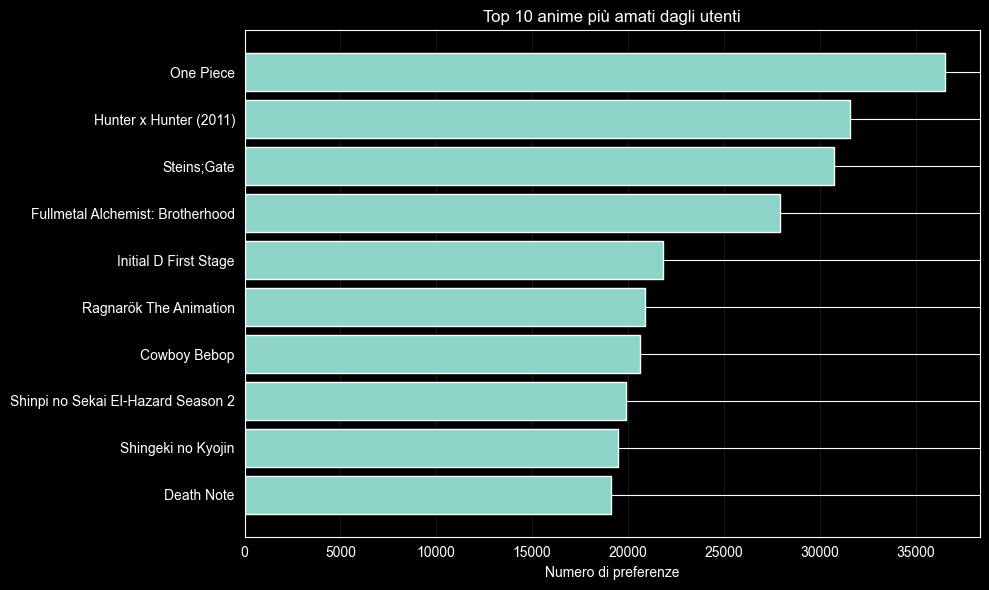

In [12]:
details = df_details.copy()
favs = df_favs.copy()
valid_mal_ids = details['mal_id'].unique()
filtered_favs = favs[favs['mal_id'].isin(valid_mal_ids)]
top_anime = (filtered_favs['mal_id'].value_counts().head(10).reset_index())
top_anime.columns = ['mal_id', 'fav_count']
top_anime = pd.merge(top_anime, details[['mal_id', 'title']], on='mal_id', how='inner')
# Sort for horizontal bar chart
top_anime = top_anime.sort_values('fav_count')
plt.figure(figsize=(10, 6))
plt.barh(top_anime['title'], top_anime['fav_count'])
plt.xlabel("Numero di preferenze")
plt.title("Top 10 anime più amati dagli utenti")
plt.grid(axis='x', alpha=0.1)

plt.tight_layout()
plt.show()

Il grafico presenta la classifica dei dieci anime più apprezzati dagli utenti, misurata attraverso il numero di preferenze. La distribuzione evidenzia una forte concentrazione verso i titoli più iconici: **One Piece** domina nettamente la classifica, con un numero di preferenze significativamente superiore agli altri, confermandosi come uno dei fenomeni più duraturi e trasversali dell’animazione giapponese.
Subito dopo compaiono **Hunter x Hunter (2011)**, **Steins;Gate** e **Fullmetal Alchemist: Brotherhood**, tre serie che, pur appartenendo a generi e periodi diversi, condividono una reputazione di alta qualità narrativa e un forte coinvolgimento del pubblico. La parte centrale della classifica include titoli come _Initial D First Stage_ e _Ragnarök The Animation_, che mostrano come anche opere meno recenti o di nicchia possano mantenere un seguito fedele.
Nelle posizioni successive troviamo serie storiche come _Cowboy Bebop_ e _El-Hazard_, insieme a titoli più moderni come _Shingeki no Kyojin_ e _Death Note_, che continuano a esercitare un impatto significativo sul pubblico globale.
Nel complesso, il grafico racconta una top 10 eterogenea, in cui convivono opere longeve, cult generazionali e successi contemporanei. Questa varietà riflette la diversità dei gusti degli utenti e la capacità dell’animazione giapponese di produrre titoli che rimangono rilevanti nel tempo.

### One Piece: qualità percepita e popolarità tra gli utenti


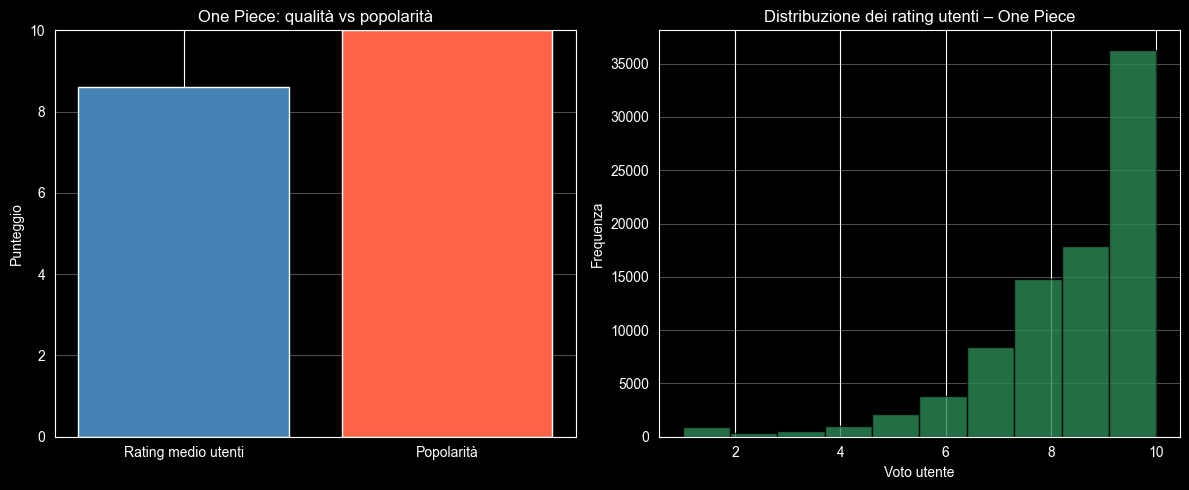

In [13]:
details = df_details.copy()
ratings = df_ratings.copy()
anime_title = "One Piece"
anime_row = details[details["title"] == anime_title]
mal_id = anime_row["mal_id"].iloc[0]
# Rimuoviamo score = 0 (utenti che non hanno votato)
anime_ratings = ratings[(ratings["anime_id"] == mal_id) & (ratings["score"] > 0)]["score"]
avg_user_rating = anime_ratings.mean()
fav_count = favs[favs["mal_id"] == mal_id].shape[0]
# Normalizzazione favs su scala 0–10
fav_score_norm = (fav_count / favs["mal_id"].value_counts().max()) * 10
# Grafici
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Qualità vs Popolarità
labels = ["Rating medio utenti", "Popolarità"]
values = [avg_user_rating, fav_score_norm]
axes[0].bar(labels, values, color=["steelblue", "tomato"])
axes[0].set_ylim(0, 10)
axes[0].set_ylabel("Punteggio")
axes[0].set_title("One Piece: qualità vs popolarità")
axes[0].grid(axis="y", alpha=0.3)
# Distribuzione rating utenti
axes[1].hist(
    anime_ratings,
    bins=10,
    color="seagreen",
    edgecolor="black",
    alpha=0.8
)
axes[1].set_xlabel("Voto utente")
axes[1].set_ylabel("Frequenza")
axes[1].set_title("Distribuzione dei rating utenti – One Piece")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Questo grafico analizza il caso di **One Piece**, mettendo a confronto la **qualità percepita dagli utenti** (rating medio) e la **popolarità**, misurata tramite il numero di preferenze (favs).

Il primo grafico evidenzia come One Piece presenti una popolarità estremamente elevata, normalizzata su una scala comparabile con il rating. Al contrario, il rating medio degli utenti risulta più moderato. Questo squilibrio suggerisce che la popolarità non dipende esclusivamente dal giudizio medio, ma anche da fattori come la longevità della serie, l’affezione emotiva del pubblico e l’impatto culturale nel tempo.

Il secondo grafico mostra la **distribuzione dei voti degli utenti**. Si osserva una forte concentrazione di voti alti (8–10), accompagnata però da una presenza significativa di voti bassi. Questo fenomeno è tipico delle opere molto popolari: attirano un pubblico ampio e diversificato, generando valutazioni più polarizzate.

Nel complesso, One Piece emerge come un esempio emblematico di come un anime possa essere **massicciamente seguito e amato**, pur non avendo un consenso uniforme sul piano della valutazione numerica.


### Gli anime con il rating più basso: cosa non ha convinto il pubblico

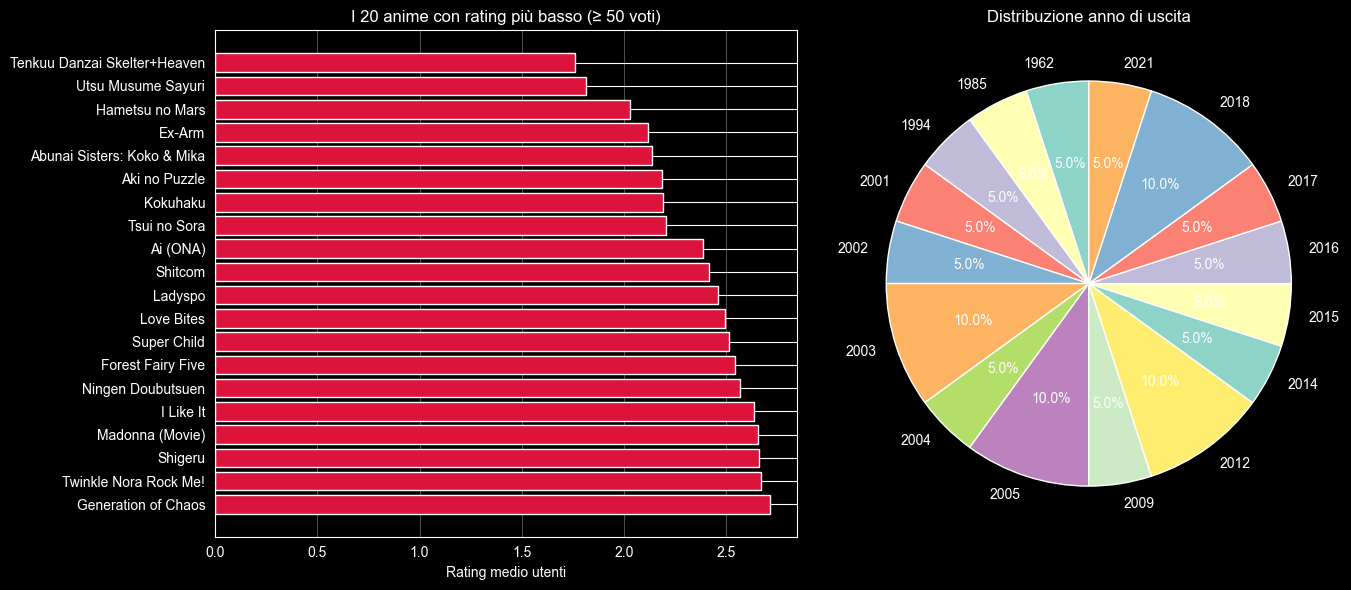

In [14]:
ratings_clean = df_ratings.copy()
ratings_clean = ratings_clean[ratings_clean["score"] > 0]
rating_stats = (ratings_clean.groupby("anime_id").agg(avg_user_score=("score", "mean"),num_votes=("score", "count")).reset_index())
# tieni solo anime con almeno 50 voti
rating_stats = rating_stats[rating_stats["num_votes"] >= 50]
anime_scores = pd.merge(
    rating_stats,
    df_details[["mal_id", "title", "year", "popularity"]],
    left_on="anime_id",
    right_on="mal_id",
    how="inner"
)
# filtro anno SENZA sovrascrivere tutto
anime_scores = anime_scores[(anime_scores["year"] >= 1917) & (anime_scores["year"] <= 2024)]
worst_20 = (anime_scores.sort_values("avg_user_score", ascending=True).head(20))
year_counts = worst_20["year"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh( worst_20["title"],worst_20["avg_user_score"],color="crimson")
axes[0].invert_yaxis()
axes[0].set_xlabel("Rating medio utenti")
axes[0].set_title("I 20 anime con rating più basso (≥ 50 voti)")
axes[0].grid(axis="x", alpha=0.3)

axes[1].pie(
    year_counts.values,
    labels=year_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Distribuzione anno di uscita")

plt.tight_layout()
plt.show()

Il grafico a sinistra presenta i venti anime con il rating medio più basso tra quelli che hanno ricevuto almeno cinquanta voti. La lista mostra una concentrazione di titoli che hanno ottenuto valutazioni particolarmente negative, con punteggi che rimangono molto bassi lungo tutta la classifica. La presenza di opere come Skelter+Heaven, Ex-Arm o Abunai Sisters evidenzia come alcuni progetti siano diventati emblematici di produzioni percepite come poco riuscite dal pubblico.
Accanto a questo, il grafico a torta sulla destra mostra la distribuzione degli anni di uscita di questi titoli. La varietà delle date che spaziano dagli anni ’60 fino agli anni più recenti indica che i prodotti mal valutati non appartengono a un’unica epoca, ma si distribuiscono lungo più decenni. Tuttavia, si nota una concentrazione maggiore in alcuni periodi, come i primi anni 2000 e la seconda metà degli anni 2010, suggerendo fasi in cui sono stati pubblicati più titoli che non hanno incontrato il favore degli utenti.
Nel complesso, i due grafici raccontano una storia complementare: da un lato una selezione di opere che rappresentano il “fondo classifica” delle valutazioni, dall’altro una distribuzione temporale che mostra come la scarsa ricezione non sia legata a un’epoca specifica, ma sia un fenomeno ricorrente nel tempo. Questo insieme offre una panoramica utile per comprendere come, accanto ai grandi successi, l’industria abbia prodotto anche titoli che non sono riusciti a soddisfare le aspettative del pubblico.

## 5. I PERSONAGGI

Dopo aver osservato gli anime più popolari, il passo successivo è capire dove si concentra l’attenzione dei fan dentro le opere.

### Personaggi principali e secondari: quantità e notorietà a confronto

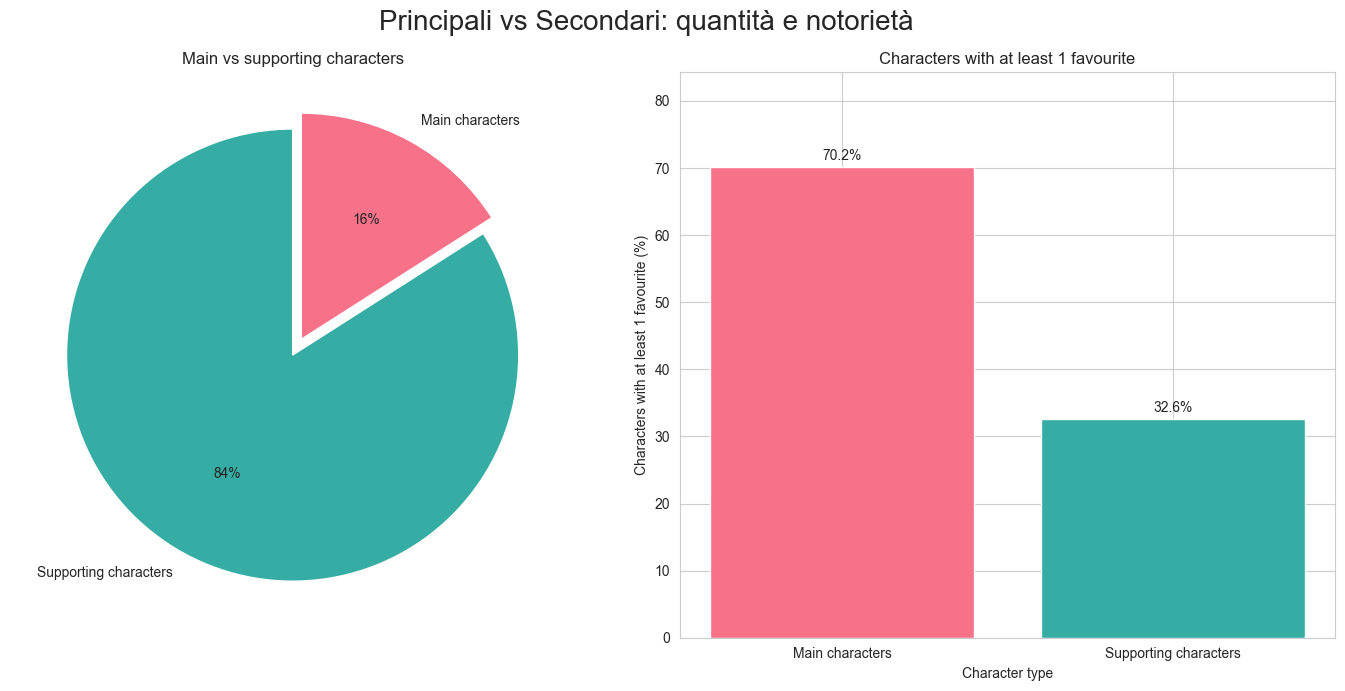

In [15]:
# preparazione dati
character_popularity = (
    df_characters_anime_works
    .loc[lambda df: df["role"].isin(["Main", "Supporting"]), ["character_mal_id", "role"]]
    .drop_duplicates()
    .groupby("character_mal_id")
    .filter(lambda x: x["role"].nunique() == 1)
    .drop_duplicates("character_mal_id")
    .rename(columns={"role": "role_group"})
    .merge(df_characters[["character_mal_id", "favorites"]], on="character_mal_id")
)
character_popularity["has_favorites"] = character_popularity["favorites"] > 0
main_support_table = (
    character_popularity.groupby("role_group")["character_mal_id"].nunique().reset_index(name="total_characters")
)
popularity_table = (
    character_popularity.groupby("role_group").agg(number_of_characters=("character_mal_id", "nunique"), characters_with_favourites=("has_favorites", "sum")
    ).assign(
        share_with_favourites=lambda df: (df["characters_with_favourites"] / df["number_of_characters"] * 100).round(1)
    ).reset_index()
)
mapping = {"Main": "Main characters", "Supporting": "Supporting characters"}
for df in [main_support_table, popularity_table]:
    df["role_group"] = pd.Categorical(df["role_group"].replace(mapping), categories=["Main characters", "Supporting characters"], ordered=True)
    df.sort_values("role_group", inplace=True)
# PLOT
plt.style.use("default")
sns.set_style("whitegrid")
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
fig.suptitle("Principali vs Secondari: quantità e notorietà ", fontsize=20)
colors = sns.color_palette("husl", 2)
# pie
ax[0].pie(
    main_support_table["total_characters"], labels=main_support_table["role_group"], autopct="%1.0f%%", startangle=90, counterclock=False, colors=colors, explode=[0.08, 0]
)
ax[0].set_title("Main vs supporting characters")
# bar
bars = ax[1].bar(
    popularity_table["role_group"], popularity_table["share_with_favourites"], color=colors
)
ax[1].bar_label(bars,
    labels=popularity_table["share_with_favourites"].astype(str) + "%", padding=3
)
ax[1].set(
    title="Characters with at least 1 favourite", xlabel="Character type", ylabel="Characters with at least 1 favourite (%)", ylim=(0, popularity_table["share_with_favourites"].max() * 1.2)
)
plt.tight_layout()
plt.show()

Il grafico confronta personaggi principali e secondari da due prospettive: quanti sono e quanto spesso ricevono almeno un preferito.
La distinzione è importante perché la quantità non coincide sempre con la notorietà. I personaggi secondari possono essere più numerosi, ma i protagonisti tendono ad avere maggiore visibilità e a costruire un legame più diretto con i fan.

## 6. I DOPPIATORI E LINGUE: LE VOCI DIETRO GLI ANIME

Un personaggio non vive solo attraverso il disegno o la storia: vive anche attraverso la voce.
Il doppiaggio dà identità ai personaggi, li rende riconoscibili e permette agli anime di arrivare a pubblici diversi.

## Quanti doppiatori hanno gli anime più amati?

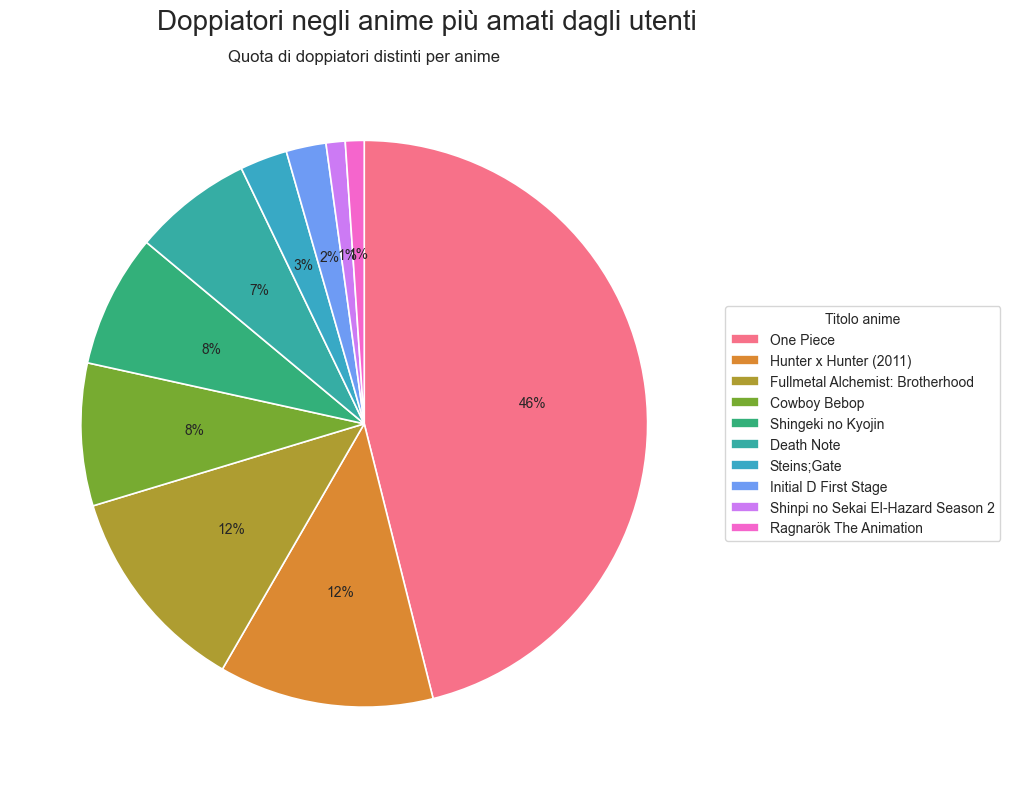

In [16]:
# preparazione dati
details = df_details.copy()
favs = df_favs.copy()
voice_works = df_person_voice_works.copy()

valid_mal_ids = details["mal_id"].unique()
filtered_favs = favs[favs["mal_id"].isin(valid_mal_ids)]

top_anime = filtered_favs["mal_id"].value_counts().head(10).reset_index()
top_anime.columns = ["mal_id", "fav_count"]

top_anime = pd.merge(
    top_anime,
    details[["mal_id", "title"]],
    on="mal_id",
    how="inner"
)

voice_actor_counts = (
    voice_works[voice_works["anime_mal_id"].isin(top_anime["mal_id"])]
    .groupby("anime_mal_id")["person_mal_id"]
    .nunique()
    .reset_index()
)

voice_actor_counts.columns = ["mal_id", "distinct_voice_actors"]

top_anime_voice = pd.merge(
    top_anime,
    voice_actor_counts,
    on="mal_id",
    how="left"
)

top_anime_voice["distinct_voice_actors"] = (
    top_anime_voice["distinct_voice_actors"]
    .fillna(0)
    .astype(int)
)

top_anime_voice = top_anime_voice.sort_values(
    "distinct_voice_actors",
    ascending=False
)

# PLOT
plt.style.use("default")
sns.set_style("whitegrid")

fig, ax = plt.subplots(figsize=(12, 8))
fig.suptitle("Doppiatori negli anime più amati dagli utenti", fontsize=20)

colors = sns.color_palette("husl", len(top_anime_voice))

wedges, texts, autotexts = ax.pie(
    top_anime_voice["distinct_voice_actors"],
    autopct="%1.0f%%",
    startangle=90,
    counterclock=False,
    colors=colors,
    wedgeprops={"edgecolor": "white", "linewidth": 1.2}
)

ax.set_title("Quota di doppiatori distinti per anime")

ax.legend(
    wedges,
    top_anime_voice["title"],
    title="Titolo anime",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.tight_layout()
plt.show()

Gli anime più amati spesso hanno cast vocali ampi, perché raccontano mondi popolati da molti personaggi.
Il numero di doppiatori aiuta quindi a vedere la complessità produttiva dietro i titoli più popolari: non solo opere amate dai fan, ma anche produzioni costruite da molte voci diverse.

## Top 10 doppiatori per personaggi distinti doppiati

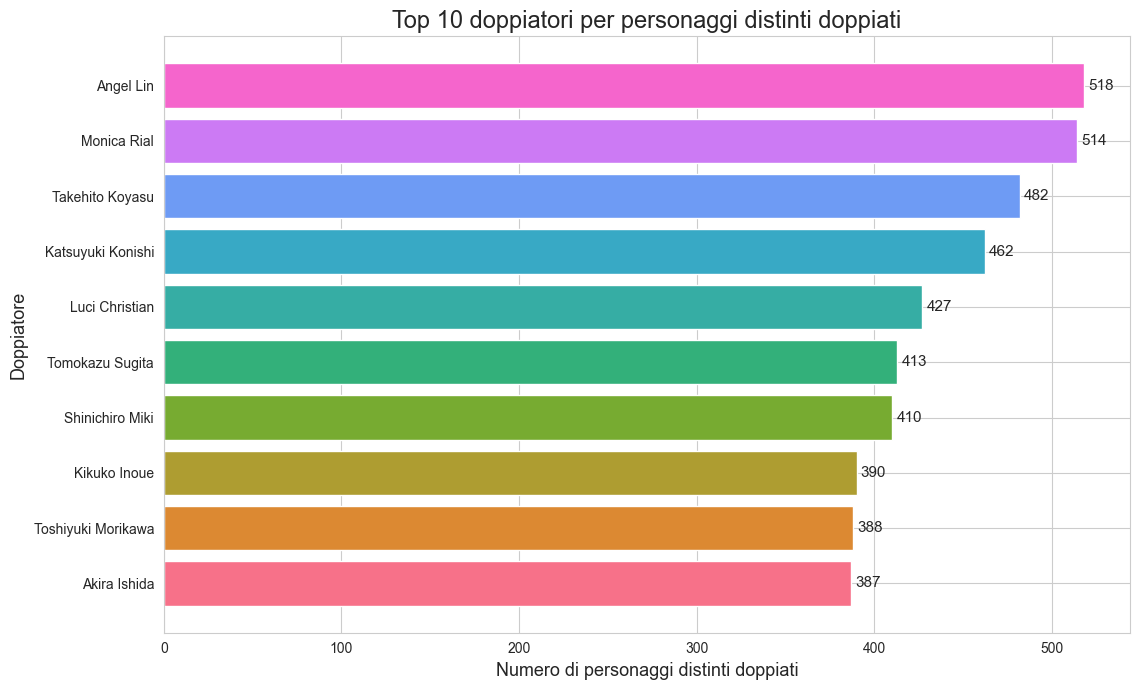

In [17]:
voice_works = df_person_voice_works.copy()
person_details = df_person_details.copy()

top_voice_actors = (
    voice_works.groupby("person_mal_id")["character_mal_id"]
    .nunique()
    .reset_index(name="distinct_dubbed_characters")
)

top_voice_actors = top_voice_actors.sort_values(
    "distinct_dubbed_characters",
    ascending=False
).head(10)

top_voice_actors = pd.merge(
    top_voice_actors, person_details[["person_mal_id", "name"]], on="person_mal_id", how="left"
)
top_voice_actors = top_voice_actors.sort_values(
    "distinct_dubbed_characters", ascending=True
)
#colori
plt.style.use("default")
sns.set_style("whitegrid")
palette = sns.color_palette("husl", len(top_voice_actors))

fig, ax = plt.subplots(figsize=(11.5, 7), facecolor="white")
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

bars = ax.barh(
    top_voice_actors["name"], top_voice_actors["distinct_dubbed_characters"], color=palette
)

ax.set_title("Top 10 doppiatori per personaggi distinti doppiati", fontsize=17)
ax.set_xlabel("Numero di personaggi distinti doppiati", fontsize=13)
ax.set_ylabel("Doppiatore", fontsize=13)
ax.bar_label(bars, padding=3, fontsize=11)
plt.tight_layout()
plt.show()

Questo grafico mostra i doppiatori associati al maggior numero di personaggi distinti.
Non misura necessariamente la fama, ma la presenza nell’ecosistema anime: alcuni professionisti compaiono più volte, attraversano opere diverse e contribuiscono a dare voce a molti personaggi.

Il doppiaggio permette agli anime di superare i confini linguistici e raggiungere community diverse.

## Le lingue più doppiate

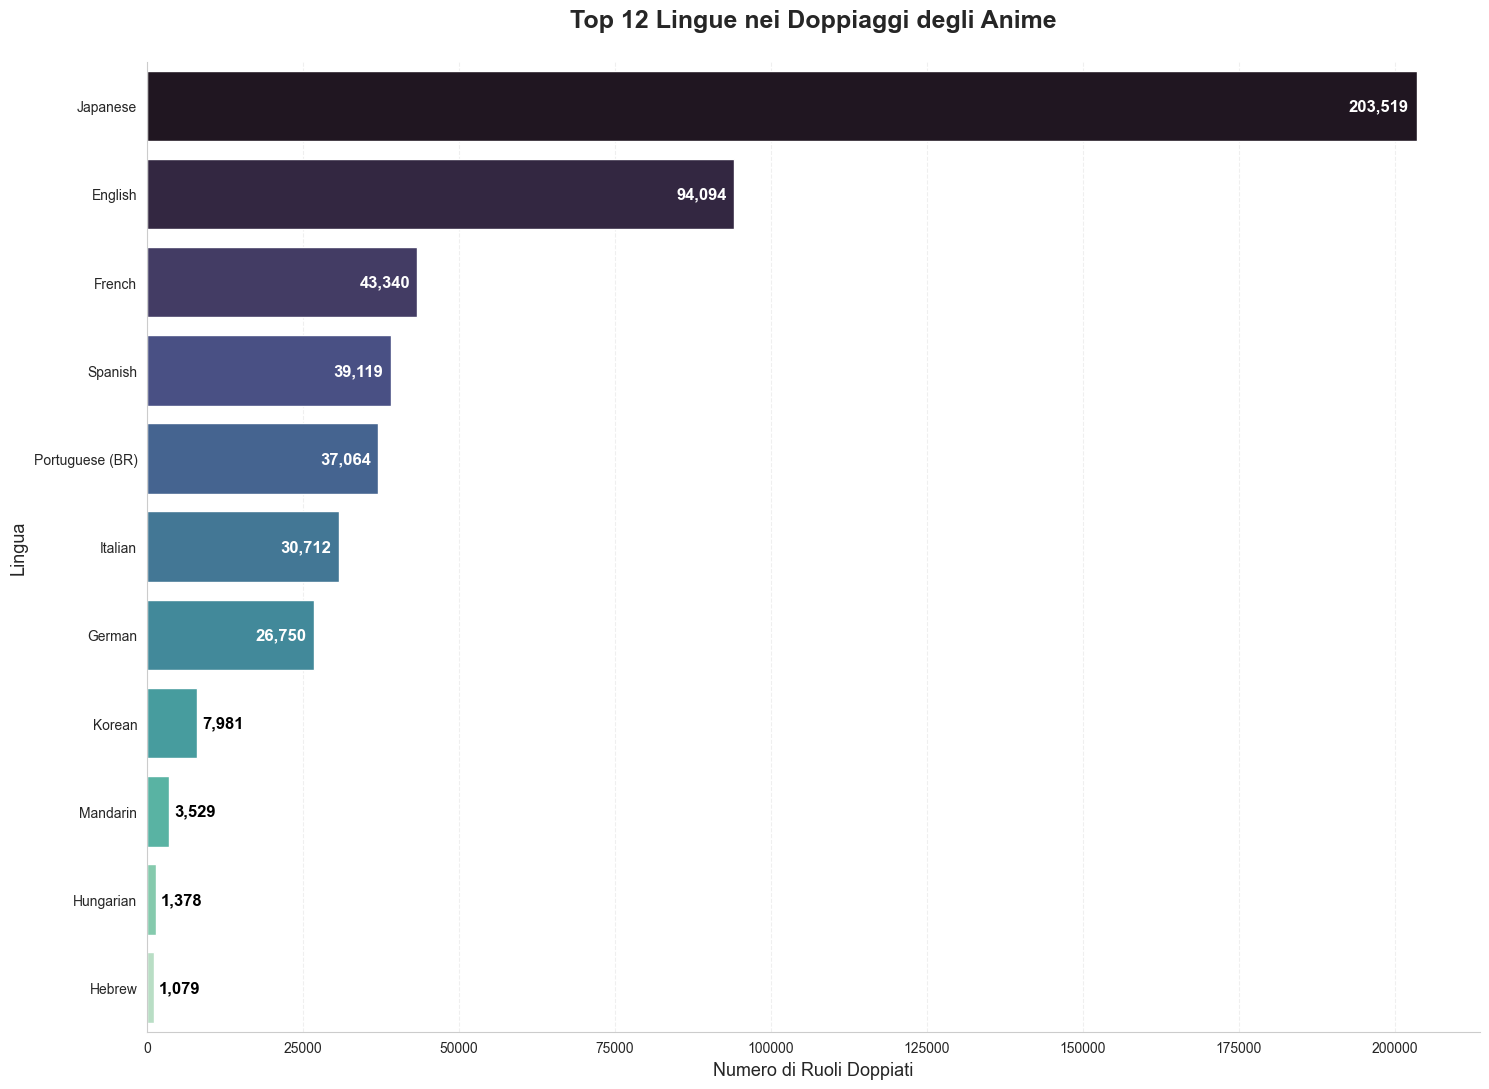

In [18]:
voice = df_person_voice_works.copy()

# Preparazione dati
lang_stats = voice.groupby('language').agg(total_roles=('character_mal_id', 'count')).sort_values('total_roles', ascending=False)
# Top 12 lingue
top12 = lang_stats.head(12).reset_index()
plt.figure(figsize=(15, 11))
sns.set_style("whitegrid")
ax = sns.barplot(data=top12,y='language',x='total_roles',palette='mako')
plt.title('Top 12 Lingue nei Doppiaggi degli Anime',fontsize=18,fontweight='bold',pad=25)
plt.xlabel('Numero di Ruoli Doppiati', fontsize=13)
plt.ylabel('Lingua', fontsize=13)

for i, row in enumerate(top12.itertuples()):

    if row.total_roles > 10000:
        # Per barre lunghe
        ax.text(x = row.total_roles - 1200,y = i, s = f"{row.total_roles:,}",
            va = 'center',ha = 'right',fontsize = 12,color = 'white',fontweight = 'bold'
        )
    else:
        # Per barre corte
        ax.text(x = row.total_roles + 800,y = i,s = f"{row.total_roles:,}",
            va = 'center',ha = 'left',fontsize = 12,color = 'black',fontweight = 'bold'
        )

# Stile pulito
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.grid(axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

Le lingue più presenti nel doppiaggio mostrano la dimensione internazionale degli anime.
Ogni lingua rappresenta un possibile pubblico: l’anime non resta legato al contesto di origine, ma viene adattato, tradotto e reso accessibile a fan di paesi e culture diverse.

## 7. Community anime nel mondo

Gli anime non crescono soltanto come produzione: crescono anche attraverso le persone che li guardano, li commentano, li valutano e li inseriscono nelle proprie liste.
Dopo aver seguito titoli, personaggi e doppiatori, la storia si sposta quindi sulla community: dove si concentra e come si è sviluppata nel tempo.

## Dov'è concentrata la community anime?

In [19]:
profiles = df_profiles.copy()

# estrazione del paese
profiles["country"] = profiles["location"].str.split(",").str[-1].str.strip()

profiles["country"] = (
    profiles["country"]
    .replace(utils.COUNTRY_FIX)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# conversione in ISO3
profiles["iso3"] = profiles["country"].apply(utils.to_iso3)

# controlli
u_total = profiles["username"].nunique()
u_loc = profiles.loc[profiles["location"].notna(), "username"].nunique()
u_iso = profiles.loc[profiles["iso3"].notna(), "username"].nunique()

print(f"Unique users: {u_total:,}")
print(f"Users with location: {u_loc:,} ({u_loc/u_total:.1%})")
print(f"Users mapped to ISO3: {u_iso:,} ({u_iso/u_total:.1%} of total)")
print(f"Coverage among users with location: {u_iso/u_loc:.1%}")

# conteggio utenti unici per paese
country_counts = (
    profiles.dropna(subset=["iso3"])
    .groupby("iso3")["username"]
    .nunique()
    .reset_index(name="n_users")
)

country_counts["log_users"] = np.log10(country_counts["n_users"] + 1)

# mappa
fig = px.choropleth(
    country_counts,
    locations="iso3",
    color="log_users",
    hover_data={"n_users": True, "log_users": ":.2f"},
    title="Dov'è concentrata la community anime?",
    color_continuous_scale=px.colors.sequential.Plasma
)

fig.update_layout(
    width=1000,
    height=600,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(color="black")
)

fig.update_coloraxes(
    colorbar_title=dict(text="log10(users)", font=dict(color="black")),
    colorbar_tickfont=dict(color="black")
)

fig.update_geos(
    showland=True,
    landcolor="lightgrey",
    showocean=True,
    oceancolor="#e6f2ff"
)

fig.show()

La mappa allarga lo sguardo e mostra la presenza della community su scala mondiale.
In questo modo la diffusione degli anime diventa visibile come fenomeno geografico: non solo pochi paesi dominanti, ma una rete di utenti distribuita in molte aree del mondo.

## I principali poli geografici della community anime

In [20]:
top6_counts = (
    profiles.groupby("country")["username"].nunique().sort_values(ascending=False).head(6).reset_index(name="n_users")
)
fig = px.bar( top6_counts, x="country", y="n_users", text="n_users", title="I principali poli geografici della community anime", labels={"country": "Country", "n_users": "Unique users"}
)
fig.update_traces(textposition="outside")
fig.update_layout(
    width=900, height=500
)
fig.update_yaxes(tickformat=".2s")
fig.update_xaxes(categoryorder="total descending")

fig.show()

Alcuni paesi concentrano una parte molto ampia della community. Questo grafico mette in evidenza i principali poli geografici degli utenti, rendendo immediatamente visibili le aree più rappresentate.


## Crescita nella community nel tempo

In [21]:
profiles = df_profiles.copy()
profiles["joined"] = pd.to_datetime(profiles["joined"], errors="coerce")
profiles["joined_year"] = profiles["joined"].dt.year
profiles["country"] = profiles["location"].str.split(",").str[-1].str.strip()

profiles = profiles.dropna(subset=["joined_year", "country"])
top_countries = (
    profiles.groupby("country")["username"].nunique().sort_values(ascending=False).head(6).index
)

trend = (
    profiles.loc[
        profiles["country"].isin(top_countries) & profiles["joined_year"].between(2005, 2024)
    ].groupby(["joined_year", "country"])["username"].nunique().reset_index(name="n_users")
)

fig = px.line(
    trend, x="joined_year", y="n_users", color="country", markers=True, title="La crescita nel tempo dei principlai poli geografici",
    labels={
        "joined_year": "Year", "n_users": "New Users", "country": "Country"
    }
)
fig.update_layout(
    width=900, height=500
)

fig.show()

Le community nazionali non crescono tutte allo stesso ritmo. Alcune aumentano prima, altre più tardi, altre ancora mostrano fasi di crescita più concentrate.
Questo grafico trasforma la geografia in una storia temporale: non mostra solo dove sono gli utenti, ma quando quelle community diventano più visibili.

## Crescita della community nel tempo a livello globale

In [22]:
df = df_profiles.copy()
df["joined"] = pd.to_datetime(df["joined"], errors="coerce")
df["joined_year"] = df["joined"].dt.year
users_per_year = (
    df.dropna(subset=["joined_year"]).groupby("joined_year")["username"].nunique().reset_index(name="new_users")
)
users_per_year["joined_year"] = users_per_year["joined_year"].astype(int)
users_per_year = users_per_year[users_per_year["joined_year"].between(2005, 2024)]
fig = px.line(
    users_per_year, x="joined_year", y="new_users", markers=True, title="Nuovi utenti registrati per anno",
    labels={
        "joined_year": "Anno", "new_users": "Nuovi utenti"
    }
)
fig.add_vrect(x0=2008, x1=2009, fillcolor="lightgrey", opacity=0.2, line_width=0)
fig.add_vrect(x0=2020, x1=2022, fillcolor="lightgrey", opacity=0.2, line_width=0)
fig.add_annotation(
    x=2008.5, y=users_per_year["new_users"].max() * 0.95, text="Crisi finanziaria", showarrow=False
)
fig.add_annotation(
    x=2021, y=users_per_year["new_users"].max() * 0.95, text="Pandemia COVID-19", showarrow=False
)
fig.update_layout(
    width=850, height=450
)
fig.show()

La crescita degli utenti registrati mostra come la community online si sia allargata nel tempo.
Questo andamento non racconta solo l’interesse verso gli anime, ma anche il modo in cui sempre più persone usano la piattaforma per seguire, valutare e organizzare la propria esperienza da fan.

Oltre alla crescita numerica, i profili degli utenti permettono di osservare anche alcune informazioni dichiarate dalla community.

## Genere più diffuso nella community anime

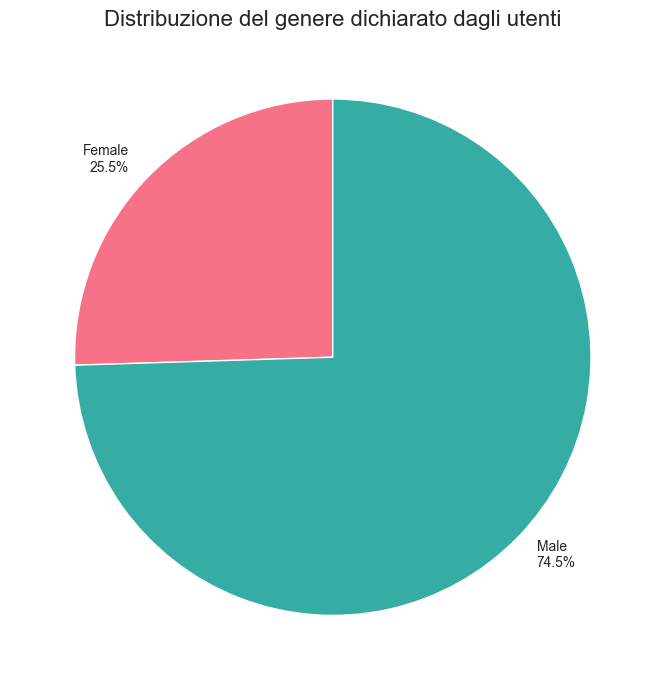

In [23]:
gender_counts = (
    profiles["gender"].value_counts().reindex(["Female", "Male", "Not declared"], fill_value=0).rename_axis("gender").reset_index(name="count")
)
gender_counts["percentage"] = (
    gender_counts["count"] / gender_counts["count"].sum() * 100
).round(1)
gender_plot = gender_counts[gender_counts["count"] > 0].copy()

labels = gender_plot["gender"] + "\n" + gender_plot["percentage"].astype(str) + "%"

plt.style.use("default")
sns.set_style("white")
palette = sns.color_palette("husl", len(gender_plot))
fig, ax = plt.subplots(figsize=(9, 7), facecolor="white")
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.pie(
    gender_plot["count"], labels=labels, colors=palette, startangle=90
)

ax.set_title("Distribuzione del genere dichiarato dagli utenti", fontsize=16)
plt.tight_layout()
plt.show()

Il genere dichiarato offre una prima lettura della composizione dei profili, ma va interpretato con cautela: non tutti gli utenti scelgono di condividere questa informazione.
Per questo il grafico racconta soprattutto ciò che gli utenti dichiarano nella piattaforma, più che una fotografia definitiva dell’intero pubblico anime.

## 8. PERSONE E RUOLI NELL'INDUSTRIA ANIME

Dietro ogni anime non ci sono solo personaggi e doppiatori, ma anche una rete più ampia di persone: autori, registi, musicisti, produttori e molte altre figure professionali.

## Da quali paesi provengono le persone che lavorano nell'industria anime

In [24]:
country_counts = df_person_details.copy()
country_counts["country"] = (
    country_counts["relevant_location"]
    .astype("string")
    .str.split(",")
    .str[-1]
    .str.strip()
)
country_counts["country"] = country_counts["country"].replace(utils.COUNTRY_FIX)
country_counts = (
    country_counts.groupby("country")["person_mal_id"]
    .nunique()
    .reset_index(name="n_people")
)
country_counts["iso3"] = country_counts["country"].apply(utils.to_iso3)
present_df = country_counts.dropna(subset=["iso3"]).copy()

fig = px.choropleth(
    present_df,
    locations="iso3",
    color="n_people",
    hover_name="country",
    title="Da quali paesi provengono i produttori degli anime?",
    color_continuous_scale=["#dff5ef", "#7fd6c2"]
)

fig.update_layout(
    width=1000,
    height=600,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(color="black")
)

fig.update_geos(
    showland=True,
    landcolor="white",
    showcountries=True,
    countrycolor="lightgrey",
    showocean=True,
    oceancolor="#f5f7fb",
    showframe=False
)

fig.show()

La geografia dei credits mostra quali paesi sono rappresentati tra le persone coinvolte nella produzione anime.

Questo passaggio è interessante perché permette di distinguere la diffusione del pubblico dalla distribuzione delle figure professionali: la community può essere globale, ma la produzione segue logiche e concentrazioni diverse.

Oltre alla provenienza geografica, possiamo osservare anche quali generazioni hanno contribuito alla costruzione dell’industria anime.

## Distribuzione Generazionale delle persone che lavorano nell'industria anime

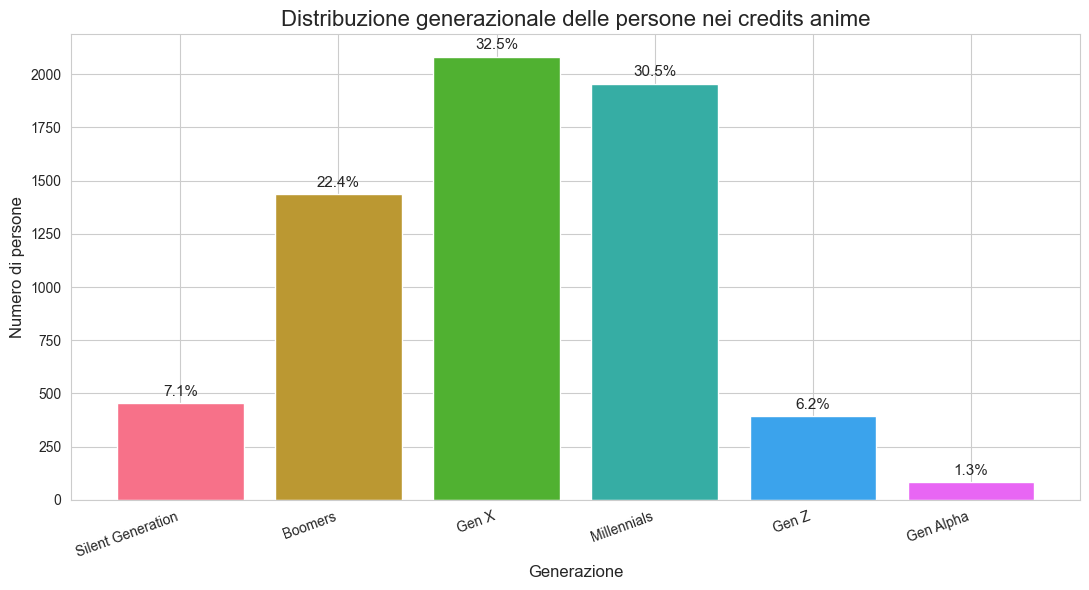

In [25]:
staff = (
    df_person_anime_works[["person_mal_id"]]
    .drop_duplicates()
    .merge(
        df_person_details[["person_mal_id", "birthday"]], on="person_mal_id",  how="left"
    )
)
staff["birth_year"] = pd.to_datetime(
    staff["birthday"], errors="coerce", utc=True
).dt.year

staff.loc[~staff["birth_year"].between(1900, 2024), "birth_year"] = pd.NA

tot_people = staff["person_mal_id"].nunique()
known_people = staff.loc[staff["birth_year"].notna(), "person_mal_id"].nunique()

labels = [
    "Silent Generation", "Boomers", "Gen X", "Millennials", "Gen Z", "Gen Alpha"
]
staff["generation"] = pd.cut(
    staff["birth_year"], bins=[-np.inf, 1945, 1964, 1980, 1996, 2012, 2024], labels=labels
)
gen_counts = (
    staff["generation"]
    .value_counts()
    .reindex(labels, fill_value=0)
    .rename_axis("generation")
    .reset_index(name="count")
)
gen_counts["share"] = (
    gen_counts["count"] / gen_counts["count"].sum() * 100
).round(1)

plt.style.use("default")
sns.set_style("whitegrid")
palette = sns.color_palette("husl", len(gen_counts))

fig, ax = plt.subplots(figsize=(11, 6), facecolor="white")
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

bars = ax.bar(
    gen_counts["generation"], gen_counts["count"], color=palette
)
ax.set_title("Distribuzione generazionale delle persone nei credits anime", fontsize=16)
ax.set_xlabel("Generazione", fontsize=12)
ax.set_ylabel("Numero di persone", fontsize=12)

labels_bar = gen_counts["share"].astype(str) + "%"

ax.bar_label(
    bars, labels=labels_bar, padding=3,  fontsize=11
)
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

La distribuzione generazionale mostra che l’industria anime è il risultato del contributo di persone nate in periodi diversi.

Questo aiuta a leggere gli anime non solo come prodotti culturali, ma anche come opere costruite nel tempo da generazioni differenti di professionisti.

## Ruoli più frequenti e notorietà nell'industria anime

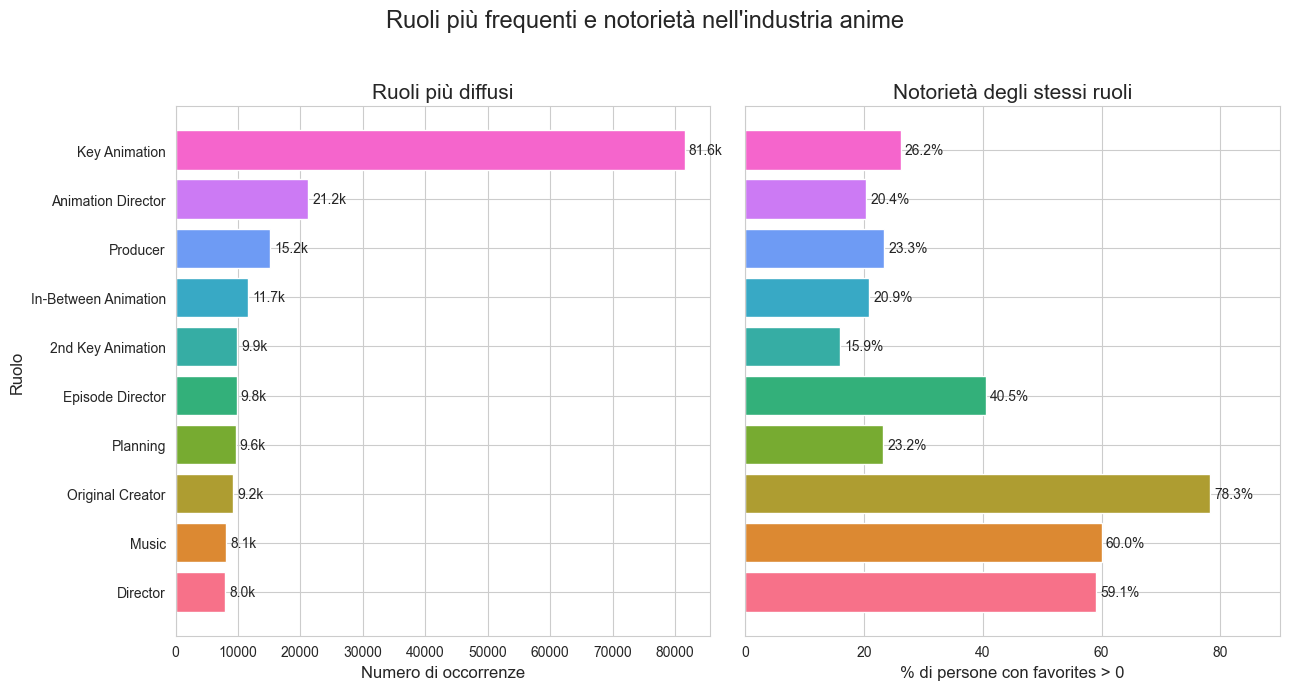

In [26]:
top10 = df_person_anime_works["position"].str.replace(r"\s*\(ep\s*\d+\)\s*$", "", regex=True).str.strip().value_counts().head(10).rename_axis("role").reset_index(name="occurrences")

role_people = df_person_anime_works.loc[
    df_person_anime_works["position"].str.replace(r"\s*\(ep\s*\d+\)\s*$", "", regex=True).str.strip().isin(top10["role"]), ["person_mal_id", "position"]
].copy()
role_people["role"] = role_people["position"].str.replace(r"\s*\(ep\s*\d+\)\s*$", "", regex=True).str.strip()
role_people = role_people.drop_duplicates(subset=["person_mal_id", "role"])
role_people = role_people.merge(df_person_details[["person_mal_id", "favorites"]], on="person_mal_id", how="left")
fav_stats = role_people.groupby("role")["favorites"].agg(share_nonzero=lambda x: (x.fillna(0) > 0).mean() * 100).reset_index()

top10 = top10.merge(fav_stats, on="role", how="left").sort_values("occurrences", ascending=True)

plt.style.use("default")
sns.set_style("whitegrid")

colors = sns.color_palette("husl", len(top10))

fig, ax = plt.subplots(1, 2, figsize=(13, 7), sharey=True, facecolor="white")
fig.patch.set_facecolor("white")

bars1 = ax[0].barh(top10["role"], top10["occurrences"], color=colors)
bars2 = ax[1].barh(top10["role"], top10["share_nonzero"], color=colors)

ax[0].set_title("Ruoli più diffusi", fontsize=15)
ax[1].set_title("Notorietà degli stessi ruoli", fontsize=15)

ax[0].set_xlabel("Numero di occorrenze", fontsize=12)
ax[1].set_xlabel("% di persone con favorites > 0", fontsize=12)
ax[0].set_ylabel("Ruolo", fontsize=12)

labels_occ = (top10["occurrences"] / 1000).round(1).astype(str) + "k"
labels_fav = top10["share_nonzero"].round(1).astype(str) + "%"

ax[0].bar_label(bars1, labels=labels_occ, padding=3, fontsize=10)
ax[1].bar_label(bars2, labels=labels_fav, padding=3, fontsize=10)

ax[1].set_xlim(0, top10["share_nonzero"].max() * 1.15)

fig.suptitle("Ruoli più frequenti e notorietà nell'industria anime", fontsize=17)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Questo grafico mette a confronto due dimensioni diverse: quanto spesso un ruolo compare nei credits e quanto le persone associate a quel ruolo risultano riconoscibili dagli utenti.

La frequenza non coincide sempre con la notorietà: alcuni ruoli sono fondamentali per la produzione, ma meno visibili al pubblico; altri, invece, riescono più facilmente a emergere nella memoria dei fan.

## 9. COME SONO SEGUITI GLI ANIME

Guardare anime non significa soltanto scegliere un titolo e valutarlo. Gli utenti costruiscono vere e proprie liste personali: anime completati, in corso, messi in pausa, abbandonati o pianificati per il futuro.

Questo blocco racconta quindi il modo in cui la community organizza il proprio rapporto con un catalogo sempre più grande.

### Tra completati, abbandonati e pianificati: lo stato di visione

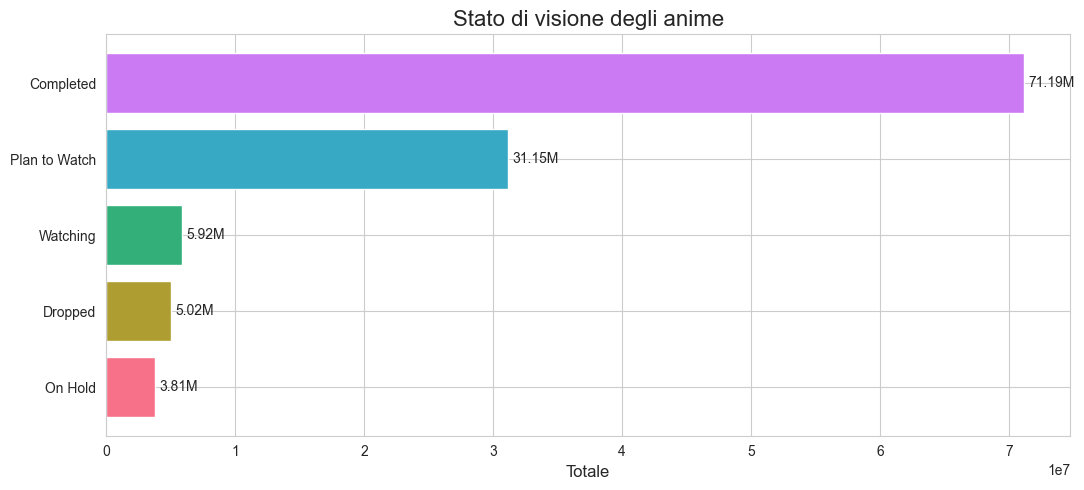

In [27]:
profiles = df_profiles.copy()

cols = utils.WATCH_STATUS_COLS
profiles[cols] = profiles[cols].fillna(0)

status_totals = profiles[cols].sum().rename_axis("status").reset_index(name="total")
status_totals["status"] = status_totals["status"].replace(utils.WATCH_STATUS_LABELS)
status_totals = status_totals.sort_values("total")

plt.style.use("default")
sns.set_style("whitegrid")
palette = sns.color_palette("husl", len(status_totals))

fig, ax = plt.subplots(figsize=(11, 5), facecolor="white")
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

bars = ax.barh(
    status_totals["status"], status_totals["total"], color=palette
)

ax.set_title("Stato di visione degli anime", fontsize=16)
ax.set_xlabel("Totale", fontsize=12)
ax.set_ylabel("")

labels_bar = (status_totals["total"] / 1000000).round(2).astype(str) + "M"
ax.bar_label(bars, labels=labels_bar, padding=3, fontsize=10)

plt.tight_layout()
plt.show()

Lo stato di visione mostra come gli utenti distribuiscono gli anime nelle proprie liste personali.

Questa visualizzazione racconta una parte concreta dell’esperienza da fan: non tutti gli anime vengono completati, alcuni restano in attesa, altri vengono abbandonati, altri ancora diventano progetti di visione futura.

## Come cambia lo stato nel tempo?

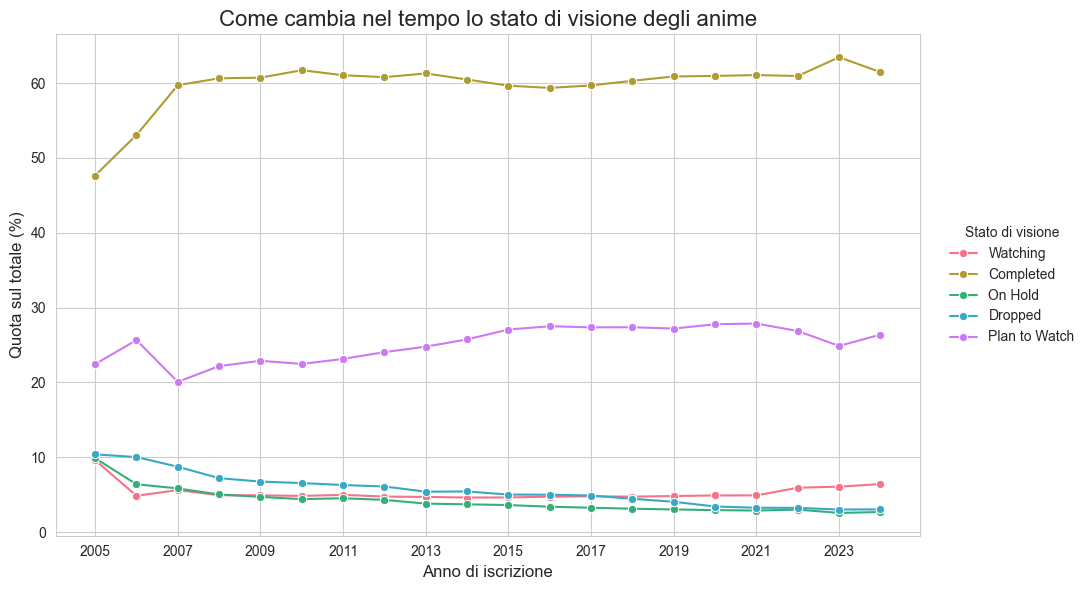

In [28]:
profiles = df_profiles.copy()

profiles["joined"] = pd.to_datetime(profiles["joined"], errors="coerce")
profiles["joined_year"] = profiles["joined"].dt.year

cols = utils.WATCH_STATUS_COLS
profiles[cols] = profiles[cols].fillna(0)

profiles = profiles.dropna(subset=["joined_year"])
profiles["joined_year"] = profiles["joined_year"].astype(int)
profiles = profiles[profiles["joined_year"].between(2005, 2024)]

status_palette = dict(zip(utils.WATCH_STATUS_ORDER, sns.color_palette("husl", len(utils.WATCH_STATUS_ORDER))))
cohort_totals = profiles.groupby("joined_year")[cols].sum().reset_index()
den = cohort_totals[cols].sum(axis=1)
cohort_pct = cohort_totals.loc[den > 0].copy()
cohort_pct[cols] = cohort_pct[cols].div(cohort_pct[cols].sum(axis=1), axis=0) * 100

cohort_long = cohort_pct.melt(
    id_vars="joined_year", value_vars=cols, var_name="status", value_name="share"
)

cohort_long["status"] = cohort_long["status"].replace(utils.WATCH_STATUS_LABELS)
plt.style.use("default")
sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(11, 6), facecolor="white")
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

sns.lineplot(
    data=cohort_long, x="joined_year", y="share", hue="status", palette=status_palette, marker="o", ax=ax
)

ax.set_title("Come cambia nel tempo lo stato di visione degli anime", fontsize=16)
ax.set_xlabel("Anno di iscrizione", fontsize=12)
ax.set_ylabel("Quota sul totale (%)", fontsize=12)

ax.set_xticks(cohort_pct["joined_year"][::2])
ax.set_xticklabels(cohort_pct["joined_year"][::2].astype(int))

ax.legend(
    title="Stato di visione", loc="center left", bbox_to_anchor=(1.02, 0.5) , frameon=False
)
plt.tight_layout()
plt.show()

Questo grafico mostra come cambia nel tempo la composizione degli stati di visione tra gli utenti registrati in anni diversi.

L’aspetto interessante non è solo quanti anime vengono guardati, ma come cambia il modo di gestirli: completare, pianificare o abbandonare un titolo diventano segnali del rapporto tra utenti e catalogo.

## 10. IL PUBBLICO A CUI SI RIVOLGONO GLI ANIME

Ogni anime non racconta solo una storia: si rivolge anche a un certo tipo di pubblico.

Dopo aver osservato produzione, popolarità, community e comportamento degli utenti, l’ultimo passaggio riguarda il target previsto: per chi vengono pensati gli anime e come questa struttura cambia nel tempo.

### Distribuzione dei target demografici

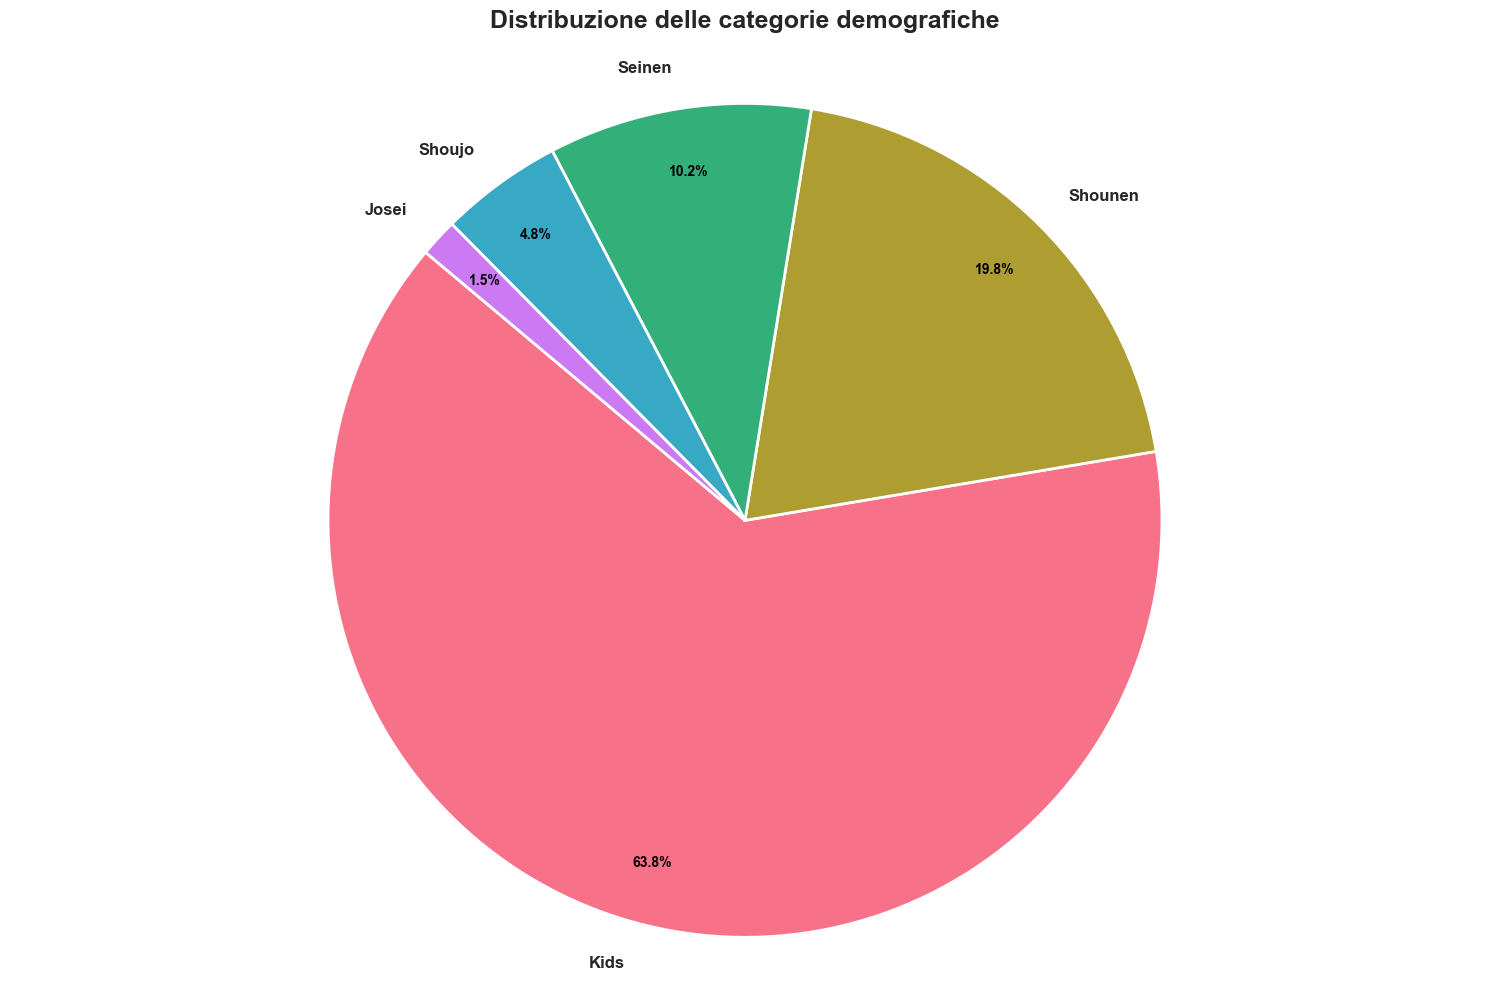

In [29]:
details_copy = df_details.copy()
details_copy = details_copy["demographics"].apply(eval).explode()

demographic_count = details_copy.value_counts()

plt.style.use("default")
sns.set_style("white")
colors = sns.color_palette("husl", len(demographic_count))

fig, ax = plt.subplots(figsize=(15, 10), facecolor="white")
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

wedges, texts, autotexts = ax.pie(
    demographic_count.values, labels=demographic_count.index, autopct="%1.1f%%",  startangle=140, colors=colors, wedgeprops={"edgecolor": "white", "linewidth": 2}, pctdistance=0.85, textprops={"fontsize": 11}
)
plt.setp(autotexts, size=10, weight="bold", color="black")
plt.setp(texts, size=12, weight="bold")
ax.set_title("Distribuzione delle categorie demografiche", fontsize=18, pad=25, fontweight="bold")
plt.axis("equal")
plt.tight_layout()
plt.show()

Le categorie demografiche mostrano a quali pubblici sono associati più spesso gli anime.

Questa lettura completa quella sui generi: mentre il genere racconta il tipo di storia, il target demografico suggerisce il pubblico a cui quella storia è principalmente indirizzata.

## Come evolgono nel tempo?

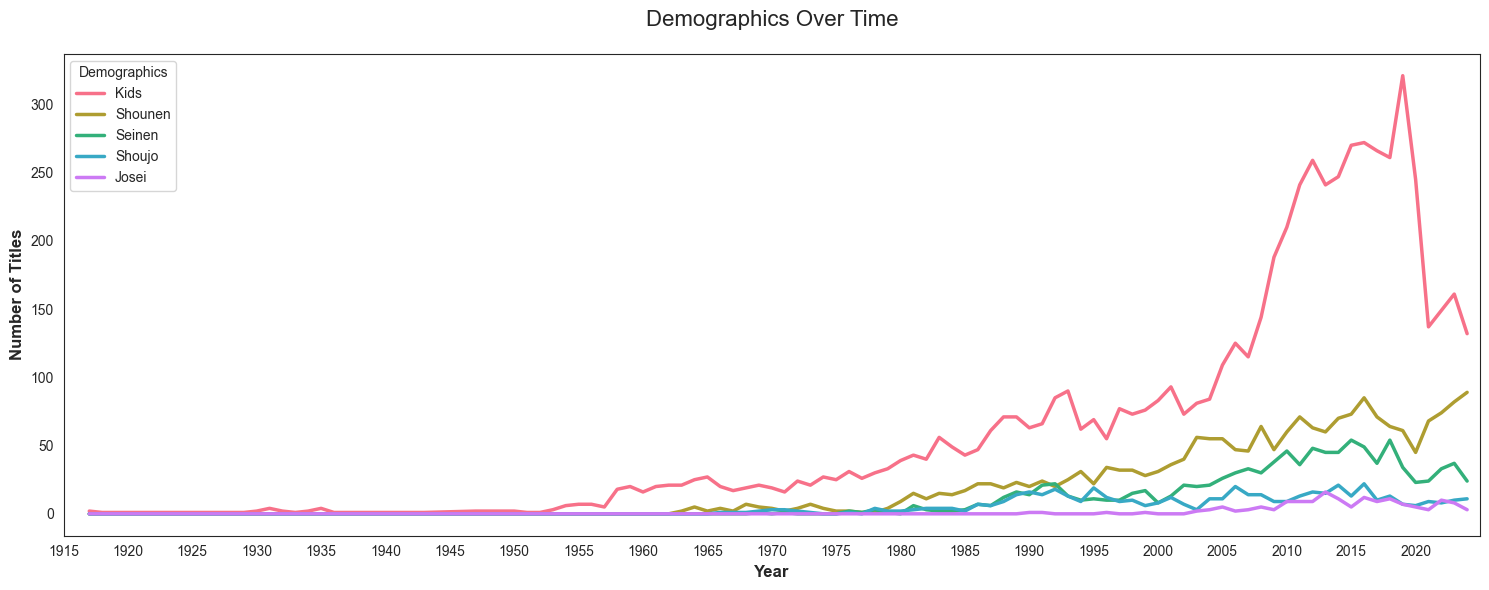

In [30]:
details_copy = df_details.copy()
details_copy = details_copy[details_copy['year'] < 2025].copy()
details_copy['demographics'] = details_copy['demographics'].apply(eval)
details_copy = details_copy.explode('demographics')
# conteggio per anno
counts = details_copy.groupby(['year', 'demographics']).size().unstack(fill_value=0).sort_index()
freq_order = details_copy['demographics'].value_counts().index
counts = counts[freq_order]
n_colors = len(counts.columns)
palette = sns.color_palette("husl", n_colors) #modificato perchè non compila, prima c'era palette = plt.cm.tab10.resampled(n)(range(n_colors))
# creazione grafico
plt.figure(figsize=(15,6))
plt.grid(linestyle=':', alpha=0.5)
counts.plot(kind='line', ax=plt.gca(), linewidth=2.5, color=palette)
# personalizzazione assi
plt.title(f'Demographics Over Time', fontsize=16, pad=20)
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Number of Titles', fontsize=12, fontweight='bold')
plt.legend(title='Demographics', loc='upper left', frameon=True)
plt.xlim(1915, 2025)
plt.xticks(ticks=range(1915, 2024, 5))

plt.tight_layout()
plt.show()


---

## 11. CONCLUSIONE - GLI ANIME COME ECOSISTEMA CULTURALE E GLOBALE

Dalla crescita della produzione ai target demografici, il percorso mostra che gli anime funzionano come un ecosistema: opere, generi, utenti, personaggi, voci e professionisti si intrecciano nel tempo, costruendo un fenomeno culturale sempre più ampio.